# Do language models keep track of what other people know?

## A key in the wrong drawer

Priya keeps the spare van key in the blue drawer. While she is out at lunch, her colleague Sam takes the key out and puts it on the shelf by the door. When Priya comes back and needs the key, she opens the blue drawer.

Anyone who hears this story can say what Priya will do, and why. She did not see the key move, so as far as she knows it is still in the drawer. Her belief is out of date, and what she does next follows from her belief, not from where the key really is.

### One detail changes the answer

The next paragraphs are an illustrative example, not a measured case.

Suppose instead that Priya ate her lunch in the meeting room next door, which has a glass wall, and she watched Sam move the key. Now she walks straight to the shelf. She was still out of the room, and the key still moved without her touching it. The only thing that changed is whether news of the move reached her.

A rule of thumb such as "whoever left the room has the wrong idea" gets the first story right and the second one wrong. To get both right, you have to follow what each person could see, hear or read, and work out what they believe from that.

Psychologists call this ability **theory of mind**: explaining and predicting what people do from what they believe and want, even when what they believe is false. Children usually manage stories like Priya's by about age five. Younger children tend to say she will look on the shelf, because that is where the key really is ([Wellman, Cross and Watson, 2001](https://doi.org/10.1111/1467-8624.00304)). That mistake, answering with what you know instead of what the other person knows, comes up again in the results.

## Why it matters for language models

Language models now write for people and for other programs, and the reader rarely knows everything the model knows.

An assistant that looks something up writes to a user who cannot see the search result. A coding agent that hands a job to a helper agent has to tell the helper about changes made after the helper started. A support assistant that writes "which of the two addresses above is right?" about a list only it can see has made Priya's mistake in reverse: it assumes the reader knows what it knows. The cost is a confused customer, a wasted round of messages, or a helper that edits a file under a name that no longer exists.

The same skill is needed to read situations correctly. A model asked whether a colleague acted carelessly, or whether someone needs to be told about a change, has to work out what that person knew at the time.

## Why the usual test no longer tells us much

The standard test is a short story like Priya's. The best-known version, the Sally-Anne test, moves a marble from a basket to a box while Sally is out of the room ([Baron-Cohen, Leslie and Frith, 1985](https://doi.org/10.1016/0010-0277(85)90022-8)). Language models have read many such stories along with their answers, and current models pass them. A high score on a story the model has seen many times can come from memory rather than from following who saw what.

Earlier research found two weak points. Models that pass the standard story can fail when one detail changes, for example when the bag is transparent ([Ullman, 2023](https://arxiv.org/abs/2302.08399)). And models that answer "does she know?" correctly can still fail to predict what she will do next, or to judge whether what she did was reasonable ([Gu et al., SimpleToM](https://arxiv.org/abs/2410.13648)).

## What this notebook does

This notebook writes new stories in code, so no model can have seen them, and asks about each story in two ways.

The first way is direct: where does Priya think the key is? The second way needs that belief without asking for it. Where will Priya look first? Was it reasonable for her to open the blue drawer? Does a colleague who saw everything need to send her a message? For a person, the answers to the second kind follow from the first. A model that gets the first kind right and the second wrong can report a belief but does not use it.

Three design choices keep the test honest.

1. Every story has a twin that differs in one detail, like the glass wall, and a model scores on a pair only if it answers both twins correctly. A rule of thumb that ignores the detail gets one twin wrong and scores nothing.
2. Every family of stories has questions with no mind in them, such as what a camera at the same spot would show, or where dye poured into a tank ends up when the pipes are wired like the office gossip. If a model gets the camera right and the person wrong, the failure is about the person.
3. The stories go well beyond keys in drawers: a phone that updates only on the office Wi-Fi, a note in a language the reader cannot read, a blind copy on an email, a helper agent working from an old copy of a project, a counter seen from the other side, and news passing along a chain of colleagues.

The notebook then turns the test around twice. The model itself plays the orchestrator and writes the follow-up message to a helper agent, and it plays an assistant that must ask a user to choose between two records the user cannot see.

## The question

Do language models differ in how well they keep track of what someone else believes when that belief differs from the truth? And does a model that answers the direct question correctly also use the belief to predict what the person will do, to judge it, and to decide what to tell them?

## Study summary

Ten language models, from three closed-model vendors and four open-weight families, each read 480 new stories: 240 twin pairs across the eight families, with Muse Wonder on 80 of the pairs because of a usage quota. For every story a model answered the direct question about a belief and, in separate calls, questions that need the belief: what the person will do, whether what they did was reasonable, and whether someone needs to tell them something. The main measure is **pair accuracy**, the share of pairs answered correctly in both twins, so a rule of thumb that ignores the deciding detail scores zero.

The models differ, mostly in using beliefs rather than stating them.

| Model | Stating the belief | Using it |
|---|---|---|
| Claude Opus 5.5 | 1.00 | 1.00 |
| Muse Wonder (80 pairs) | 1.00 | 1.00 |
| GPT-6.1 Sol | 0.99 | 1.00 |
| DeepSeek V4.1 Flash | 0.99 | 0.93 |
| Qwen3.8 27B | 0.98 | 0.91 |
| Muse Spark | 0.98 | 0.97 |
| Nemotron 3.5 Super VL | 0.89 | 0.86 |
| Claude Haiku 5.5 | 0.80 | 0.82 |
| GPT-6 Luna | 0.69 | 0.48 |
| Granite 4.2 8B | 0.52 | 0.29 |

Unreadable replies were rare, at most 31 of a model's 3,084 answers (Nemotron 3.5 Super VL), and are counted as wrong; counting them as right instead leaves the order of the models unchanged.

The errors go mostly one way. Every model is at least 90% accurate when the person missed the change. When the person saw it, read the note or heard the announcement, the weaker models still say the person holds the old belief: Granite 4.2 8B gets 51% of those answers right and GPT-6 Luna 73%. That is the answer the classic story always rewards, and a test made only of classic stories would have scored both models at about 90%.

In Priya's terms: every model knows she will open the blue drawer when she missed the move. The top models also know she will go to the shelf when she watched through the glass. The weakest two would often send her to the drawer anyway, and would often be wrong about whether her colleague needs to message her.

The main caveat: the three strongest models answered almost every question correctly (Claude Opus 5.5 missed 1 of 3,084 answers, GPT-6.1 Sol 6, and Muse Wonder 2 of 1,034), so this test cannot rank them or show where their ability ends. The stories are generated from templates that state every rule, which is easier than real writing, where much is left unsaid.

## Contents

1. [Setup and configuration](#1-setup-and-configuration)
2. [The stories](#2-the-stories)
3. [How the models are asked and scored](#3-how-the-models-are-asked-and-scored)
4. [The models](#4-the-models)
5. [Running the models](#5-running-the-models)
6. [Results: how many answers could be read](#6-results-how-many-answers-could-be-read)
7. [Results: stating a belief and using it](#7-results-stating-a-belief-and-using-it)
8. [Results: family by family](#8-results-family-by-family)
9. [Results: people against cameras, copies and water tanks](#9-results-people-against-cameras-copies-and-water-tanks)
10. [Results: which twin goes wrong](#10-results-which-twin-goes-wrong)
11. [Results: short and long stories](#11-results-short-and-long-stories)
12. [Results: when the model is the one who must tell](#12-results-when-the-model-is-the-one-who-must-tell)
13. [Error analysis with examples](#13-error-analysis-with-examples)
14. [How the study got here](#14-how-the-study-got-here)
15. [Limitations](#15-limitations)
16. [How to reproduce, and what it cost](#16-how-to-reproduce-and-what-it-cost)
17. [Future work and further reading](#17-future-work-and-further-reading)

### How the experiment runs

Each box says what goes in and what comes out. One pair travels through it like this. The generator writes device-S01 twice, once where Yara reads the app in a café before her phone has downloaded a change (twin A) and once where she reads it in the office after the download (twin B), with the right answer to every question. Each twin becomes four calls: the control and explicit questions together, then the behaviour, judgement and action questions one at a time. Each model answers all eight calls. The scorer turns each letter back into an option, marks it correct, wrong or unreadable, and then pairs the twins: the explicit pair score for device-S01 is 1 only if the model said "Gate 5" in twin A and "Gate 3" in twin B.

```mermaid
flowchart TD
    G["Story generator (Python, no language model)<br/>8 families x 2 lengths x 15 pairs = 240 pairs, 480 stories<br/>answers from a record of who saw, heard or read what"] --> C
    C["Calls for each story<br/>controls + explicit questions in one call; behaviour, judgement, action one per call<br/>1,832 calls per model, plus 6 hidden-tool items"] --> M
    M["10 models, one reply per call, every reply cached<br/>claude -p, codex exec, muse exec, OpenRouter"] --> S
    S["Scorer: letter to option; correct, wrong or unreadable<br/>pair score: right in both twins"] --> R
    R["Results: stating vs using a belief, family by family,<br/>people vs cameras and water tanks, which twin goes wrong"]
```

## 1. Setup and configuration

The notebook replays every model answer from the caches in `data/`, so running it needs no keys and costs nothing. Setting `NB_LIVE=1` allows new calls, capped by `MAX_OPENROUTER_USD` and `MAX_CLI_CALLS`. `N_PAIRS` sets the size of the study: 15 pairs for each of the eight story families and two story lengths, 240 pairs in all.

In [1]:
import hashlib, itertools, json, math, os, random, re, shutil, subprocess, tempfile, textwrap, threading, time, uuid
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display, Markdown

ROOT = Path.cwd()
DATA, FIG = ROOT / 'data', ROOT / 'figures'
DATA.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)
LIVE = os.environ.get('NB_LIVE') == '1'  # explicit opt-in; without it a cache miss stops the notebook

# Size knobs. Every model answer is cached in data/, so a re-run with LIVE off costs nothing.
N_PAIRS = 15                 # pairs per family and story length: 8 families x 2 lengths x 15 = 240 pairs
MODELS = ['Claude Opus 5.5', 'Claude Haiku 5.5', 'GPT-6.1 Sol', 'GPT-6 Luna', 'Muse Wonder', 'Muse Spark',
          'DeepSeek V4.1 Flash', 'Nemotron 3.5 Super VL', 'Qwen3.8 27B', 'Granite 4.2 8B']
EFFORT = 'medium'            # reasoning effort for every model
N_PAIRS_BY_MODEL = {'Muse Wonder': 5}  # fewer pairs: Muse Wonder shares a subscription quota with Muse Spark
MAX_OPENROUTER_USD = 30.0    # hard stop for new OpenRouter spend
MAX_CLI_CALLS = 15000        # hard stop for new claude, codex and muse calls
PROTOCOL = 'nb29-v1'         # part of every cache key

# One plot style for this notebook.
COLORS = {'blue': '#2468ac', 'orange': '#dc793a', 'green': '#3a9175', 'purple': '#8d63ad', 'grey': '#9a9a9a',
          'red': '#c0392b', 'light': '#d9d9d9', 'dark': '#333333'}
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight', 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.2, 'axes.axisbelow': True,
                     'axes.titlelocation': 'left', 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'font.size': 9,
                     'figure.facecolor': 'white'})
pd.set_option('display.max_colwidth', 160)
print('LIVE' if LIVE else 'Replay from cache', '|', len(MODELS), 'models |', N_PAIRS, 'pairs per family and length')

Replay from cache | 10 models | 15 pairs per family and length


## 2. The stories

Every story is written by a short Python program, not by a language model. The program keeps two records as the story unfolds: what is true (where the key is, what the board says, who received which email) and what each person has seen, heard or read. The answers to every question come from those records, so they are exact and can be checked by reading the code.

### Twins

Each story comes in a pair. Twin A and twin B are word-for-word the same except for one detail, and that detail changes the answer to the main questions. In Priya's case the detail is the solid wall against the glass wall. A model earns a point for a pair only when it answers the question correctly in both twins. A model that always says "the old place" gets twin A right and twin B wrong; a model that always says "where the key really is" does the opposite. Both score 0 on pairs, while guessing between two options would score 25%.

### Five kinds of question

Each story is followed by questions at five levels.

| Level | Example (Priya's key) | What it checks |
|---|---|---|
| Control | Where is the key now? Where did Priya first put it? | That the model followed the events. No mind is involved. |
| Explicit | Where does Priya think the key is? | The belief, asked for directly. |
| Behaviour | Priya wants the key. Where will she look first? | Using the belief to predict an action. |
| Judgement | Priya went straight to the blue drawer. Given what she knew, was that reasonable? | Using the belief to judge an action. |
| Action | A colleague who saw everything will message Priya only if she would otherwise look in the wrong place. Does the colleague need to? | Using the belief to decide what someone else should do. |

The behaviour, judgement and action questions never mention belief. Each is sent to the model in a separate call, so the model cannot copy its explicit answer from earlier in the same reply. This follows the finding from SimpleToM that reminding a model of its belief answer makes the later questions easier.

### Short and long stories

Every family has a short version and a long version. Long versions add events that do not matter to the answer (a second object being moved about, people taking phone calls), clock times, and a question about what the person believed at an earlier time. In two families the long version also changes the facts twice, so that in twin B the person's belief is an in-between value that is neither the starting state nor the true one. Section 14 explains why those two were made harder after a small trial run.

### Eight families

The families below differ in how information reaches a person or fails to. The first is a deliberately familiar shape, kept as a reference. The others were chosen because stories with their structure are rare in published text, so a model cannot answer them from a remembered pattern.

The next cell holds the parts every family shares: names, places, objects, the question helper and the clock.

In [2]:
PEOPLE = ['Priya', 'Tomasz', 'Ines', 'Kofi', 'Mei', 'Rafael', 'Aiko', 'Dara', 'Lucia', 'Oskar', 'Nadia', 'Emeka',
          'Sunniva', 'Joaquin', 'Hana', 'Bram', 'Yusuf', 'Freya', 'Matteo', 'Zainab', 'Ilya', 'Rosa', 'Kwame',
          'Leilani', 'Anders', 'Thandi', 'Viktor', 'Amara', 'Callum', 'Noor', 'Teodor', 'Esme', 'Bao', 'Marisol',
          'Henrik', 'Adaeze', 'Silas', 'Yara', 'Dmitri', 'Wren']

SETTINGS = [
    {'place': 'the back office of a bicycle repair co-op',
     'containers': ['the red toolbox', 'the drawer under the counter', 'the biscuit tin on the shelf', 'the canvas bag by the door'],
     'objects': ['the spare shop key', 'the torque wrench', 'the receipt book', 'the tyre gauge'],
     'leave': ['to collect a delivery', 'to fix a puncture out front', 'to take a phone call outside']},
    {'place': 'the reading room of a seed library',
     'containers': ['the oak card cabinet', 'the green crate', 'the top drawer of the desk', 'the envelope box'],
     'objects': ['the packet of rare bean seeds', 'the catalogue stamp', 'the volunteer rota', 'the label printer'],
     'leave': ['to meet a donor at the gate', 'to water the trial beds', 'to fetch more envelopes']},
    {'place': 'a community radio studio',
     'containers': ['the cable crate', 'the cupboard by the door', 'the crate above the mixing desk', 'the blue backpack'],
     'objects': ['the spare microphone', 'the studio USB stick', 'the guest list', 'the headphone adapter'],
     'leave': ['to greet a guest in reception', 'to buy coffee', 'to check the aerial on the roof']},
    {'place': 'a pottery studio',
     'containers': ['the glaze cupboard', 'the plastic tub under the wheel', 'the apron pocket on the hook', 'the tin by the kiln'],
     'objects': ['the kiln key', 'the trimming tool', 'the order book', 'the sponge on a stick'],
     'leave': ['to unload clay from the van', 'to answer the door', 'to post a parcel']},
    {'place': 'a mountain hut',
     'containers': ['the wooden chest', 'the rucksack by the bunk', 'the drawer in the map table', 'the tin above the stove'],
     'objects': ['the radio battery', 'the hut logbook', 'the first-aid scissors', 'the head torch'],
     'leave': ['to fetch water from the stream', 'to check the weather station', 'to split firewood']},
    {'place': 'a ferry ticket office',
     'containers': ['the cash drawer', 'the cupboard behind the counter', 'the shoebox under the desk', 'the filing tray'],
     'objects': ['the spare ticket roll', 'the master key card', 'the lost-property ledger', 'the card reader'],
     'leave': ['to help a passenger on the quay', 'to collect the post', 'to move the van']},
    {'place': 'a theatre prop room',
     'containers': ['the hat box', 'the props trunk', 'the basket by the mirror', 'the drawer of the sewing table'],
     'objects': ['the brass pocket watch', "the stage manager's torch", 'the prompt script', 'the fake moustache'],
     'leave': ['to watch a scene from the wings', 'to meet the lighting crew', 'to collect costumes']},
    {'place': 'the back office of a vet clinic',
     'containers': ['the grey locker', 'the top drawer of the reception desk', 'the box under the scales', 'the cupboard by the sink'],
     'objects': ['the microchip scanner', 'the appointment diary', 'the spare collar', 'the nail clippers'],
     'leave': ['to help with a nervous dog', 'to take a delivery', 'to call a client back']},
    {'place': 'a bakery',
     'containers': ['the flour bin', 'the drawer by the till', 'the tin on the windowsill', 'the cupboard under the sink'],
     'objects': ['the oven thermometer', 'the cash-up sheet', 'the cake stencil', 'the piping bag'],
     'leave': ['to serve a customer', 'to take bins out', 'to collect eggs from the supplier']},
    {'place': 'a print shop',
     'containers': ['the paper cabinet', 'the drawer of the cutting table', 'the box by the laminator', 'the tray over the sink'],
     'objects': ['the guillotine key', 'the proof folder', 'the ink cartridge', 'the bone folder'],
     'leave': ['to deliver posters next door', 'to fetch lunch', 'to fix the van door']},
]
LANGUAGES = ['Finnish', 'Hungarian', 'Welsh', 'Basque', 'Estonian', 'Icelandic']
YES, NO = 'Yes', 'No'


def cap(s):
    return s[0].upper() + s[1:]


def clock(m):
    return f'{m // 60}:{m % 60:02d}'


def after_time(text):
    """Lower-case a sentence's first word after 'At 9:30,' unless it is a name."""
    first = text.split(' ', 1)[0].strip(',.')
    return text if first in PEOPLE else text[0].lower() + text[1:]


def Q(qid, level, text, options, answer, tags=None, call=None):
    """One multiple-choice question. `answer` is the correct option text; `tags` labels options for error analysis."""
    assert answer in options and len(set(options)) == len(options), (qid, options, answer)
    return {'qid': qid, 'level': level, 'text': text, 'options': list(options), 'answer': answer,
            'tags': tags or {}, 'call': call or ('base' if level in ('control', 'explicit') else level)}


class Timeline:
    """Story sentences, optionally prefixed with clock times."""
    def __init__(self, start, timed):
        self.t, self.timed, self.lines = start, timed, []

    def ev(self, text, gap=10):
        self.lines.append((self.t, text))
        self.t += gap
        return self.t - gap

    def render(self):
        if not self.timed:
            return ' '.join(text for _, text in self.lines)
        return ' '.join(f'At {clock(t)}, {after_time(text)}' for t, text in self.lines)


def location_ladder(X, Z, obj, c1, c2, c3, belief, two_moves=False):
    """Controls, belief, behaviour, judgement and action for a story where obj ends in c2. With two_moves it went
    c1 -> c3 -> c2, so a belief can be the old place, the intermediate place or the true one."""
    opts = [c1, c2, c3]
    tags = {c1: 'old', c2: 'reality', c3: 'intermediate' if two_moves else 'other'}
    ok = f'Yes, it was reasonable given what {X} knew'
    bad = f'No, {X} had reason to know it was not there'
    qs = [
        Q('reality', 'control', f'Where is {obj} now?', opts, c2),
        Q('start', 'control', f'Where did {X} first put {obj}?', opts, c1),
        Q('belief', 'explicit', f'Where does {X} think {obj} is now?', opts, belief, tags),
        Q('look', 'behaviour', f'{X} wants {obj}. Where will {X} look for it first?', opts, belief, tags),
        Q('fair', 'judgement', f'{X} went straight to {c1} to get {obj}. Given what {X} knew, was that reasonable?',
          [ok, bad], ok if belief == c1 else bad, {ok: 'old', bad: 'reality'}),
    ]
    if not two_moves:  # after two moves the person is wrong in both twins, so this question would not flip
        qs.append(Q('help', 'action', f'{Z}, who saw and heard everything that happened, will send {X} a message only '
                    f'if {X} would otherwise look in the wrong place for {obj}. Does {Z} need to send the message?',
                    [YES, NO], YES if belief != c2 else NO, {YES: 'old', NO: 'reality'}))
    return qs


def distractor_script(rng, people, obj2, conts, start):
    """Moves of a second object and other small events; the same script is used in both twins."""
    where, script = start, []
    for _ in range(rng.randint(3, 5)):
        p, kind = rng.choice(people), rng.random()
        if kind < 0.6:
            dest = rng.choice([c for c in conts if c != where])
            script.append(f'{p} takes {obj2} out of {where} and puts it in {dest}.')
            where = dest
        elif kind < 0.8:
            script.append(f'{p} opens {rng.choice(conts)}, looks inside and closes it again without taking anything.')
        else:
            script.append(f'{p} answers the phone and takes a message for someone else.')
    return script, where


def setup_location(rng):
    s = rng.choice(SETTINGS)
    X, Y, Z, W = rng.sample(PEOPLE, 4)
    obj, obj2 = rng.sample(s['objects'], 2)
    c1, c2, c3 = rng.sample(s['containers'], 3)
    return s, X, Y, Z, W, obj, obj2, c1, c2, c3


def finish_location(qs, long, obj2, conts, where2, X, obj, t_query, belief, two_moves=False):
    """Long stories add a control on the second object and a belief question at a past time."""
    if long:
        qs.insert(2, Q('reality2', 'control', f'Where is {obj2} now?', conts, where2))
        if t_query is not None:
            qs.insert(4, Q('belief_t', 'explicit', f'At {clock(t_query)}, where did {X} think {obj} was?', conts, belief,
                           {conts[0]: 'old', conts[1]: 'reality', conts[2]: 'intermediate' if two_moves else 'other'}))
    return qs

### Family 1: the classic story (reference)

This family is the Sally-Anne story in new words. One person puts an object in a container. In twin A they go out and someone else moves the object; in twin B they watch the move and then go out. Places (a pottery studio, a ferry ticket office, a mountain hut) and objects are drawn at random from ten settings.

A third colleague "stays in the room all day and sees and hears everything". That person is needed for the action question, which asks whether they need to send a message.

This family measures how a model does on the familiar shape. Comparing it with the other seven shows how much a model relies on that shape.

In [3]:
def gen_classic(rng, long, subtype=None):
    s, X, Y, Z, W, obj, obj2, c1, c2, c3 = setup_location(rng)
    reason = rng.choice(s['leave'])
    script, where2 = distractor_script(rng, [Y, W], obj2, [c1, c2, c3], c3)
    start = rng.randrange(8 * 60, 10 * 60, 5)
    twins = {}
    for twin in 'AB':
        tl = Timeline(start, long)
        intro = (f'{X}, {Y}, {Z} and {W} are working in {s["place"]}. {Z} stays in the room all day and sees and '
                 f'hears everything that happens there.')
        tl.ev(f'{X} puts {obj} in {c1}.')
        if long:
            tl.ev(f'{W} puts {obj2} in {c3}.')
        if twin == 'A':
            tl.ev(f'{X} goes out {reason}.', 15)
            t_move = tl.ev(f'{Y} takes {obj} out of {c1} and puts it in {c2}.')
            for line in (script if long else []):
                tl.ev(line)
            tl.ev(f'{X} comes back into the room.')
        else:
            t_move = tl.ev(f'{Y} takes {obj} out of {c1} and puts it in {c2} while {X} watches.')
            for line in (script if long else []):
                tl.ev(line)
            tl.ev(f'{X} goes out {reason}.', 15)
            tl.ev(f'{X} comes back into the room.')
        belief = c1 if twin == 'A' else c2
        qs = finish_location(location_ladder(X, Z, obj, c1, c2, c3, belief), long, obj2, [c1, c2, c3], where2,
                             X, obj, t_move + 5, belief)
        twins[twin] = {'story': intro + ' ' + tl.render(), 'questions': qs}
    return 'saw the move or not', {'A': f'{X} is out when it moves', 'B': f'{X} watches it move, then goes out'}, twins

### Family 2: information that arrives but is not taken in

Being in the room is not the same as knowing. This family varies whether information that reaches a person is actually taken in, in five ways.

| Subtype | Twin A (does not take it in) | Twin B (takes it in) |
|---|---|---|
| language | a note in a language the person cannot read | the same note in English |
| headphones | told out loud while wearing headphones | told after taking them off |
| facing away | in the room, back turned, during a quiet move | in the room, facing the shelves |
| glass wall | out of the room, solid walls | out of the room behind a glass wall, watching |
| asleep | asleep on a bunk | lying awake, watching |

The glass-wall twins catch the "absent means wrong" rule of thumb; the headphones, facing-away and asleep twins catch "present means informed". In the long version the object then moves a second time while the person is out, so in twin B the person believes the in-between place.

In [4]:
UPTAKE_SUBTYPES = ['language', 'headphones', 'facing away', 'glass wall', 'asleep']


def gen_uptake(rng, long, subtype=None):
    """Short stories: one move, which the person does or does not take in. Long stories: the object then moves a
    second time while the person is out, so in twin B the person's belief is the intermediate place."""
    s, X, Y, Z, W, obj, obj2, c1, c2, c3 = setup_location(rng)
    reason, reason2 = rng.sample(s['leave'], 2)
    lang = rng.choice(LANGUAGES)
    subtype = subtype or rng.choice(UPTAKE_SUBTYPES)
    script, where2 = distractor_script(rng, [Y, W], obj2, [c1, c2, c3], c3)
    start = rng.randrange(8 * 60, 10 * 60, 5)
    first = c3 if long else c2  # where the first move takes the object
    twins = {}
    for twin in 'AB':
        tl = Timeline(start, long)
        rules = ''
        intro = (f'{X}, {Y}, {Z} and {W} are working in {s["place"]}. {Z} stays in the room all day and sees and '
                 f'hears everything that happens there.')
        tl.ev(f'{X} puts {obj} in {c1}.')
        if long:
            tl.ev(f'{W} puts {obj2} in {c3}.')
        if subtype == 'language':
            rules = f' {X} reads only English. {Y} is learning {lang} and sometimes writes notes in it.'
            tl.ev(f'{X} goes out {reason}.', 15)
            tl.ev(f'{Y} takes {obj} out of {c1} and puts it in {first}.')
            note = lang if twin == 'A' else 'English'
            tl.ev(f"{Y} leaves a note on {X}'s desk, written in {note}, saying that {obj} is now in {first}.")
            for line in (script if long else []):
                tl.ev(line)
            t_query = tl.ev(f'{X} comes back, picks up the note and looks at it.') + 5
            detail = {'A': f'the note is in {lang}', 'B': 'the note is in English'}
        elif subtype == 'headphones':
            rules = f' With headphones on, {X} cannot hear anything said in the room.'
            tl.ev(f'{X} goes out {reason}.', 15)
            tl.ev(f'{Y} takes {obj} out of {c1} and puts it in {first}.')
            for line in (script if long else []):
                tl.ev(line)
            tl.ev(f'{X} comes back and sits down at the desk ' +
                  ('with headphones on.' if twin == 'A' else 'and takes the headphones off.'))
            t_query = tl.ev(f'{Y} says out loud, "I have put {obj} in {first}," and goes home.') + 5
            detail = {'A': f'{X} keeps headphones on', 'B': f'{X} takes headphones off'}
        elif subtype == 'facing away':
            facing = (f"with {X}'s back to the rest of the room" if twin == 'A'
                      else f'facing the rest of the room, which {X} can see over the laptop')
            tl.ev(f'{X} sits down at the desk for a long video call, {facing}.', 15)
            t_query = tl.ev(f'{Y} quietly takes {obj} out of {c1} and puts it in {first}.') + 5
            for line in (script if long else []):
                tl.ev(line)
            tl.ev(f'{X} finishes the call.')
            detail = {'A': f'{X} sits with back to the room', 'B': f'{X} sits facing the room'}
        elif subtype == 'glass wall':
            wall = ('The meeting room has solid walls.' if twin == 'A' else
                    f'The meeting room has a glass wall that looks onto this room, and {X} sits facing it.')
            tl.ev(f'{X} goes into the meeting room next door for a call. {wall}', 15)
            t_query = tl.ev(f'{Y} takes {obj} out of {c1} and puts it in {first}.') + 5
            for line in (script if long else []):
                tl.ev(line)
            tl.ev(f'{X} comes back from the meeting room.')
            detail = {'A': 'the meeting room has solid walls', 'B': f'the meeting room has a glass wall {X} faces'}
        else:
            lie = ('lies down on the bunk in the corner and falls asleep.' if twin == 'A' else
                   'lies down on the bunk in the corner and stays awake, watching the room.')
            tl.ev(f'{X} {lie}', 15)
            t_query = tl.ev(f'{Y} quietly takes {obj} out of {c1} and puts it in {first}.') + 5
            for line in (script if long else []):
                tl.ev(line)
            tl.ev(f'{X} gets up from the bunk.')
            detail = {'A': f'{X} is asleep', 'B': f'{X} lies awake, watching'}
        if long:  # a second move that the person cannot know about in either twin
            tl.ev(f'{X} goes out {reason2}.', 15)
            tl.ev(f'{W} takes {obj} out of {c3} and puts it in {c2}.')
            tl.ev(f'{X} comes back into the room.')
        belief = c1 if twin == 'A' else first
        qs = finish_location(location_ladder(X, Z, obj, c1, c2, c3, belief, two_moves=long), long, obj2,
                             [c1, c2, c3], where2, X, obj, t_query, belief, two_moves=long)
        twins[twin] = {'story': intro + rules + ' ' + tl.render(), 'questions': qs}
    return subtype, detail, twins

### Family 3: a device and a person

A team keeps a date, a gate number or a meeting room on a shared board in a phone app. The rules are stated in the story: a phone downloads the latest board only while it is on the office Wi-Fi, and a person sees the board only by opening the app.

Someone changes the board while the person is out. In one subtype the person comes back briefly, the phone updates, and the person either opens the app (twin B) or does not (twin A). In twin A the phone now shows the new value but the person still believes the old one. In the other subtype the person reads the app in a café before the phone has updated (twin A), or in the office after it has (twin B). Every story ends "she does not open the app again today", so the person cannot be assumed to check again.

The controls ask what the phone would show, now and at 10:15. A phone has no beliefs, so these are the non-mental counterpart of the belief question: a model that treats "her phone has it" as "she knows it" gets twin A wrong. In the long version the board changes a second time after the person has left, so twin B's belief is the in-between value.

In [5]:
FACTS = [
    {'fact': 'the launch day', 'values': ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday'],
     'team': 'product team', 'behave': 'Which day does {X} block out in the calendar for the launch?'},
    {'fact': 'the departure gate for the 16:40 ferry', 'values': ['Gate 2', 'Gate 3', 'Gate 5', 'Gate 7', 'Gate 9'],
     'team': 'harbour crew', 'behave': 'Which gate does {X} walk to for the 16:40 ferry?'},
    {'fact': "the room for Thursday's rehearsal", 'values': ['Studio B', 'the Long Room', 'the Loft', 'the Green Room', 'Hall 4'],
     'team': 'theatre company', 'behave': "Where does {X} go for Thursday's rehearsal?"},
    {'fact': "the start time of Saturday's market shift", 'values': ['6:30', '7:00', '8:15', '9:30', '10:00'],
     'team': 'market co-op', 'behave': "For what time does {X} plan to arrive at Saturday's market shift?"},
    {'fact': 'the pickup point for the field trip', 'values': ['the north car park', 'the bus shelter', 'the library steps', 'the old gate', 'the canal bridge'],
     'team': 'school staff', 'behave': 'Where does {X} go to meet the field-trip coach?'},
]


def gen_device(rng, long, subtype=None):
    f = rng.choice(FACTS)
    X, Y, Z, W = rng.sample(PEOPLE, 4)
    v1, v2, v3 = rng.sample(f['values'], 3)
    subtype = subtype or rng.choice(['looked or not after sync', 'looked before or after sync'])
    errand = rng.choice(['a client visit', 'the dentist', 'a site walk', 'a supplier meeting'])
    fetch = rng.choice(['pick up a charger', 'drop off a parcel', 'collect a jacket', 'sign a form'])
    w_back = rng.random() < 0.5  # long stories: does W come back to the office (so W's phone syncs)?
    rules = (f'The {f["team"]} keeps {f["fact"]} on a shared board in an app. A phone downloads the latest version '
             f'of the board only while it is connected to the office Wi-Fi. A person sees what is on the board only '
             f'by opening the app on their phone.')
    intro = f'{X}, {Y}, {Z} and {W} are in the {f["team"]}. {Z} knows everything that happens today.'
    twins = {}
    for twin in 'AB':
        ev = [(9 * 60, f'{X}, {Y} and {W} open the app in the office. The board says {f["fact"]} is {v1}.'),
              (9 * 60 + 30, f'{X} leaves the office for {errand}.'),
              (10 * 60, f'{Y}, in the office, changes {f["fact"]} on the board to {v2}.')]
        if long:
            ev.append((9 * 60 + 45, f'{W} leaves the office for lunch.'))
            if w_back:
                ev.append((10 * 60 + 20, f'{W} comes back to the office from lunch but does not open the app.'))
        back = f"{X} comes back to the office for five minutes to {fetch}, and {X}'s phone connects to the office Wi-Fi."
        if subtype == 'looked or not after sync':
            ev.append((10 * 60 + 30, back + (f' {X} does not open the app, and leaves again.' if twin == 'A'
                                             else f' {X} opens the app, reads the board, and leaves again.')))
            detail = {'A': f'{X} does not open the app while back', 'B': f'{X} opens the app while back'}
        else:
            ev.append((10 * 60 + 15, f'{X}, sitting in a café, opens the app and reads the board.' if twin == 'A'
                       else f'{X}, sitting in a café, checks email but does not open the app.'))
            ev.append((10 * 60 + 30, back + (f' {X} does not open the app again, and leaves.' if twin == 'A'
                                             else f' {X} opens the app, reads the board, and leaves again.')))
            detail = {'A': f'{X} reads the app in the café, before the phone syncs',
                      'B': f'{X} reads the app in the office, after the phone syncs'}
        if long:  # a second change after X has left again: X's phone keeps the intermediate value
            ev.append((10 * 60 + 45, f'{Y} changes {f["fact"]} on the board again, to {v3}.'))
        ev.sort()
        story = (intro + ' ' + rules + ' ' + ' '.join(f'At {clock(t)}, {after_time(x)}' for t, x in ev)
                 + f' {X} does not open the app again today.')
        belief = v1 if twin == 'A' else v2
        now = v3 if long else v2
        opts = [v1, v2, v3]
        tags = {v1: 'old', v2: 'intermediate', v3: 'reality'} if long else {v1: 'old', v2: 'reality', v3: 'other'}
        ok, bad = f'Yes, it was reasonable given what {X} knew', f'No, {X} had reason to know it had changed'
        qs = [Q('board', 'control', f'What does the board say {f["fact"]} is now?', opts, now),
              Q('phone', 'control', f"If someone opened the app on {X}'s phone right now, what would it show for {f['fact']}?", opts, v2),
              Q('phone_t', 'control', f"If someone had opened the app on {X}'s phone at 10:15, what would it have shown for {f['fact']}?", opts, v1),
              Q('belief', 'explicit', f'What does {X} think {f["fact"]} is?', opts, belief, tags),
              Q('plan', 'behaviour', f['behave'].format(X=X), opts, belief, tags),
              Q('fair', 'judgement', f'{X} planned around {v1}. Given what {X} knew, was that reasonable?', [ok, bad],
                ok if belief == v1 else bad, {ok: 'old', bad: 'reality'})]
        if not long:  # after two changes X is out of date in both twins, so this question would not flip
            qs.append(Q('help', 'action', f'{Z} will message {X} only if {X} would otherwise plan around the wrong value '
                        f'for {f["fact"]}. Does {Z} need to message {X}?', [YES, NO], YES if belief != v2 else NO,
                        {YES: 'old', NO: 'reality'}))
        if long:
            qs.insert(3, Q('phone_w', 'control', f"If someone opened the app on {W}'s phone right now, what would it show for {f['fact']}?",
                           opts, v3 if w_back else v1))
        twins[twin] = {'story': story, 'questions': qs}
    return subtype, detail, twins

### Family 4: knowing that something changed, but not what

Most belief tests have two answers: the person is right or wrong. Here there is a third: the person knows something changed but not what it changed to.

In one subtype a door code is changed and posted in a chat the person has muted. At lunch a colleague mentions that the code changed but not the new number (twin A), or talks about the weekend (twin B). The story states what the person does when unsure: phone the front desk before trying the door.

In the other subtype, every drawer has a small screen showing who last opened it. Someone opens the person's drawer to take a pencil (twin A) or opens a different drawer (twin B). Nothing is moved in either twin, so the object is exactly where the person left it. Only in twin B is the person entitled to be sure of that. The judgement question tests the difference between being right and having reason to be sure.

In [6]:
KEYPAD_PLACES = ['the reading room of a seed library', 'a community radio studio', 'a ferry ticket office',
                 'the back office of a vet clinic', 'a print shop']
DOORS = [('the storeroom keypad', 'storeroom'), ('the bike-shed keypad', 'bike shed'), ('the back-door keypad', 'back door'),
         ('the archive-room keypad', 'archive room')]


def gen_partial(rng, long, subtype=None):
    subtype = subtype or rng.choice(['told it changed', 'last-opened screen'])
    X, Y, Z, W = rng.sample(PEOPLE, 4)
    twins = {}
    if subtype == 'told it changed':
        s = rng.choice([x for x in SETTINGS if x['place'] in KEYPAD_PLACES])
        door, short = rng.choice(DOORS)
        old, new, other = [f'{n:04d}' for n in rng.sample(range(1000, 10000), 3)]
        for twin in 'AB':
            tl = Timeline(0, False)
            intro = (f'{X}, {Y}, {Z} and {W} work at {s["place"]}. {Z} knows everything that happens today. Until '
                     f'today the code for {door} was {old}. When {X} knows a code has changed but does not know the '
                     f'new code, {X} phones the front desk before trying the door.')
            tl.ev(f'In the morning, {Y} changes the code for {door} to {new} and posts the new code in the team chat.')
            tl.ev(f'{X} has the team chat muted and does not open it today.')
            if long:
                tl.ev(f'{W} reads the team chat and replies with a thumbs-up.')
                tl.ev(f'{Y} also posts that the {short} light is broken.')
            tl.ev(f'At lunch, {W} tells {X}, "{Y} changed the {short} code this morning," but does not say the new code.'
                  if twin == 'A' else f'At lunch, {W} and {X} talk about the weekend.')
            tl.ev(f'In the evening, {X} goes to the {short}.')
            o_old, o_new = f'{X} thinks the code is still {old}', f'{X} knows the new code, {new}'
            o_part = f'{X} knows the code has changed but does not know the new code'
            b_old, b_new, b_ask = f'Types {old}', f'Types {new}', 'Phones the front desk'
            ok, bad = f'Yes, it was reasonable given what {X} knew', f'No, {X} had reason to know the code had changed'
            qs = [Q('code_now', 'control', f'What is the code for {door} now?', [old, new, other], new),
                  Q('code_before', 'control', f'What was the code for {door} before today?', [old, new, other], old),
                  Q('belief', 'explicit', f'Which best describes what {X} knows about the code?', [o_old, o_new, o_part],
                    o_part if twin == 'A' else o_old, {o_old: 'old', o_new: 'reality', o_part: 'partial'}),
                  Q('act', 'behaviour', f'{X} reaches the {short}. What does {X} do first?', [b_old, b_new, b_ask],
                    b_ask if twin == 'A' else b_old, {b_old: 'old', b_new: 'reality', b_ask: 'partial'}),
                  Q('fair', 'judgement', f'{X} typed {old} and set off the alarm. Given what {X} knew, was that reasonable?',
                    [ok, bad], bad if twin == 'A' else ok, {ok: 'old', bad: 'partial'}),
                  Q('help', 'action', f'{Z} will phone {X} only if {X} would otherwise type the old code. Does {Z} need to phone {X}?',
                    [YES, NO], NO if twin == 'A' else YES)]
            twins[twin] = {'story': intro + ' ' + tl.render(), 'questions': qs}
        detail = {'A': f'{W} tells {X} the code changed, without the number', 'B': f'{W} does not mention the code'}
    else:
        s = rng.choice(SETTINGS)
        obj, obj2 = rng.sample(s['objects'], 2)
        c1, c2, c3 = rng.sample(s['containers'], 3)
        for twin in 'AB':
            tl = Timeline(0, False)
            intro = (f'{X}, {Y}, {Z} and {W} work at {s["place"]}. {Z} sees everything that happens today. Each '
                     f'drawer, box and cupboard here has a small screen on the front that shows the name of the last '
                     f'person who opened it. When {X} is not sure an item is still where {X} left it, {X} checks the '
                     f'sign-out sheet before going to look.')
            tl.ev(f'{X} puts {obj} in {c1} and closes it.')
            if long:
                tl.ev(f'{W} puts {obj2} in {c3}.')
            tl.ev(f'{X} goes out for the afternoon.')
            tl.ev(f'{Y} opens {c1}, takes out a pencil, and closes it again. {cap(obj)} stays where it is.' if twin == 'A'
                  else f'{Y} opens {c3}, takes out a pencil, and closes it again.')
            if long:
                tl.ev(f'{W} opens {c2}, looks inside, and closes it again.')
                tl.ev(f'{W} takes {obj2} out of {c3} and puts it in {c2}.')
            tl.ev(f'{X} comes back and glances at the screen on {c1}.')
            o_sure = f'{X} is sure {obj} is still in {c1}'
            o_unsure = f'{X} is not sure {obj} is still in {c1}, because someone has opened {c1} since'
            o_moved = f'{X} thinks {obj} has been moved to {c3}'
            b_go, b_sheet, b_other = f'Goes straight to {c1}', 'Checks the sign-out sheet', f'Goes to {c3}'
            yes_e, no_e = f'Yes, {X} was entitled to be that sure', f'No, {X} had reason to doubt it'
            qs = [Q('reality', 'control', f'Where is {obj} now?', [c1, c2, c3], c1),
                  Q('screen', 'control', f'Whose name does the screen on {c1} show when {X} comes back?', [X, Y, W], Y if twin == 'A' else X),
                  Q('belief', 'explicit', f'Which best describes what {X} believes about {obj}?', [o_sure, o_unsure, o_moved],
                    o_unsure if twin == 'A' else o_sure, {o_sure: 'reality', o_unsure: 'partial', o_moved: 'other'}),
                  Q('act', 'behaviour', f'{X} needs {obj}. What does {X} do first?', [b_go, b_sheet, b_other],
                    b_sheet if twin == 'A' else b_go, {b_go: 'reality', b_sheet: 'partial', b_other: 'other'}),
                  Q('fair', 'judgement', f'Right after glancing at the screen, and before opening anything, {X} told a '
                    f'visitor, "It is definitely in {c1}." '
                    f'Given what {X} knew, was {X} entitled to be that sure?', [yes_e, no_e], no_e if twin == 'A' else yes_e,
                    {yes_e: 'reality', no_e: 'partial'})]
            if long:
                qs.insert(2, Q('reality2', 'control', f'Where is {obj2} now?', [c1, c2, c3], c2))
            twins[twin] = {'story': intro + ' ' + tl.render(), 'questions': qs}
        detail = {'A': f'{Y} opens the same drawer, so the screen shows {Y}', 'B': f'{Y} opens a different one, so the screen still shows {X}'}
    return subtype, detail, twins

### Family 5: who knows that who knows

Office news travels through channels that leave different traces: an email with names on the CC line, a blind copy (BCC) that nobody else can see, a forwarded email, a group chat, two private messages, a remark in a corridor with or without someone else listening. The story states the rules: people know only what they see, hear or read, and a blind copy is invisible to everyone but the sender.

The questions go up to three levels: "Does Rosa know that Wren knows that Rosa knows the night shift is being dropped?" The program answers them from a small record of who knows what. An event shared by a group (a corridor conversation, a CC'd email) makes its content known to everyone in the group, together with the fact that everyone in the group knows it, up to three levels. A blind copy tells the copied person what the visible group knows, while nobody but the sender learns that the copy was sent.

The behaviour question uses a stated habit ("Tomasz only brings up news with people Tomasz thinks have not heard it yet"), and the judgement question asks whether "You won't have heard yet, but..." was a reasonable thing to say.

In [7]:
NEWS = ['the Lisbon office will close in March', 'the Halden contract has been cancelled', 'the spring budget has been cut by a fifth',
        'the move to the new building is delayed until June', 'the night shift is being dropped', 'the Ostrava client wants a new quote']


def K(agent, f):
    return ('K', agent, f)


def wrap(chain, f):
    for a in reversed(chain):
        f = K(a, f)
    return f


class Epistemic:
    """Who knows what, up to three levels deep ("A knows that B knows that C knows p").
    An announcement makes its content common knowledge in the group, cut off at DEPTH levels. A blind-copy
    recipient learns what the visible group shares, the sender knows they received it, and nobody else does."""
    DEPTH = 3

    def __init__(self, people):
        self.kb = {p: set() for p in people}

    def chains(self, group, n):
        for k in range(n + 1):
            yield from itertools.product(sorted(group), repeat=k)

    def announce(self, group, f):
        for a in group:
            for ch in self.chains(group, self.DEPTH - 1):
                self.kb[a].add(wrap(ch, f))

    def email(self, sender, visible, bcc, f):
        vis = {sender, *visible}
        self.announce(vis, f)
        for h in bcc:
            for ch in self.chains(vis, self.DEPTH - 1):
                self.kb[h].add(wrap(ch, f))
            self.kb[sender].add(K(h, f))
            for ch in self.chains(vis, self.DEPTH - 2):
                self.kb[sender].add(K(h, wrap(ch, f)))
            self.kb[h].add(K(sender, K(h, f)))

    def forward(self, by, to, original_visible, f):
        for ch in self.chains(original_visible, self.DEPTH - 1):
            self.kb[to].add(wrap(ch, f))
        self.announce({by, to}, f)

    def knows(self, a, f):
        return f in self.kb[a]


def kq(qid, ep, chain, p, text_p):
    """'Does A know that B knows ... that p?', answered from the epistemic record."""
    who = chain[0]
    phrase = ' that '.join([f'{who} know'] + [f'{a} knows' for a in chain[1:]])
    yes, no = YES, f'No, nothing {who} has seen, heard or read shows {who} this'
    return Q(qid, 'explicit', f'Does {phrase} that {text_p}?', [yes, no],
             yes if ep.knows(who, wrap(chain[1:], p)) else no, {yes: 'yes', no: 'no'})


NESTED_SCHEMAS = ['blind copy or visible copy', 'corridor with or without sender', 'forward to one person or another',
                  'group chat or private messages']


def gen_nested(rng, long, subtype=None):
    S, T, P, W, V = rng.sample(PEOPLE, 5)
    news = rng.choice(NEWS)
    other = rng.choice([n for n in NEWS if n != news])
    p, q = ('p',), ('q',)
    schema = subtype or rng.choice(NESTED_SCHEMAS)
    rule = ('People here know only what they see, hear or read for themselves. On an email, everyone can see the names '
            'on the To and CC lines, but nobody except the sender can see who was sent a blind copy (BCC).')
    twins = {}
    for twin in 'AB':
        ep = Epistemic([S, T, P, W, V])
        lines = []
        intro = f'{S}, {T}, {P} and {W} work together.' + (f' {V} works in the same building.' if long else '')
        if long:
            lines.append(f'{S} emails {W} and {V} that {other}.')
            ep.email(S, [W, V], [], q)
        policy = None
        if schema == 'blind copy or visible copy':
            if twin == 'A':
                lines.append(f'{S} emails {T} that {news}, and sends {P} a blind copy (BCC).')
                ep.email(S, [T], [P], p)
            else:
                lines.append(f'{S} emails {T} that {news}, with {P} on the CC line.')
                ep.email(S, [T, P], [], p)
            if long:
                lines.append(f'{W} mentions to {P} in the kitchen that {other}.')
                ep.announce({W, P}, q)
            lines.append(f'Later, {T} and {P} have lunch together.')
            names = [f'{S} and {T} only', f'{S}, {T} and {P}']
            qs = [Q('names', 'control', f'Whose names can {T} see on the email from {S}?', names, names[twin == 'B']),
                  kq('k2', ep, [T, P], p, news), kq('k3', ep, [P, T, P], p, news), kq('k2b', ep, [P, T], p, news),
                  kq('k2c', ep, [S, P], p, news)]
            policy = (T, P)
        elif schema == 'corridor with or without sender':
            lines.append(f'{S} emails {T} that {news}, and sends {P} a blind copy (BCC).')
            ep.email(S, [T], [P], p)
            if long:
                lines.append(f'{V} tells {S} that {other}.')
                ep.announce({V, S}, q)
            if twin == 'A':
                lines.append(f'That afternoon, {P} mentions the news to {T} in the corridor. Nobody else is around.')
                ep.announce({P, T}, p)
            else:
                lines.append(f'That afternoon, {P} mentions the news to {T} in the corridor, while {S} is standing with them and hears it.')
                ep.announce({P, T, S}, p)
            who = [f'{P} and {T} only', f'{P}, {T} and {S}']
            knows3 = ep.knows(S, wrap([T, P], p))
            ok, bad = f'Yes, it was reasonable given what {S} knew', f'No, {S} knew {T} already knew'
            qs = [Q('who', 'control', f'Who was in the corridor when {P} mentioned the news?', who, who[twin == 'B']),
                  kq('k3', ep, [S, T, P], p, news), kq('k2', ep, [T, P], p, news), kq('k2b', ep, [S, P], p, news),
                  Q('tell', 'behaviour', f'{S} plans to tell {T} that {P} has heard the news, but only if {S} does not '
                    f'already know that {T} knows this. Will {S} tell {T}?', [YES, NO], NO if knows3 else YES),
                  Q('fair', 'judgement', f'That evening, {S} wrote to {T}: "Just so you know, {P} has heard the news." '
                    f'Given what {S} knew, was that message reasonable?', [ok, bad], bad if knows3 else ok)]
        elif schema == 'forward to one person or another':
            lines.append(f'{S} emails {T}, and only {T}, that {news}.')
            ep.email(S, [T], [], p)
            dest = W if twin == 'A' else P
            if long:
                lines.append(f'{P} tells {V} at the bus stop that {other}.')
                ep.announce({P, V}, q)
            lines.append(f'{T} forwards the email to {dest}.')
            ep.forward(T, dest, {S, T}, p)
            lines.append(f'Later, {T} and {P} have lunch together.')
            qs = [Q('fwd', 'control', 'Who received the forwarded email?', [W, P], dest),
                  kq('k1', ep, [P], p, news), kq('k2', ep, [T, P], p, news), kq('k2b', ep, [P, S], p, news),
                  kq('k2c', ep, [S, P], p, news)]
            policy = (T, P)
        else:
            if twin == 'A':
                lines.append(f'{S} posts in the team group chat, which has {T}, {P} and {W} in it, that {news}.')
                ep.announce({S, T, P, W}, p)
            else:
                lines.append(f'{S} sends {T} a private message that {news}, and then sends {P} a separate private '
                             f'message saying the same.')
                ep.announce({S, T}, p)
                ep.announce({S, P}, p)
            if long:
                lines.append(f'{W} sends {V} a private message that {other}.')
                ep.announce({W, V}, q)
            lines.append(f'Later, {T} and {P} have lunch together.')
            how = ['One message in the group chat', 'Two private messages']
            qs = [Q('how', 'control', f'How did {S} share the news?', how, how[twin == 'B']),
                  kq('k2', ep, [T, P], p, news), kq('k2b', ep, [P, T], p, news), kq('k1', ep, [T], p, news)]
            policy = (T, P)
        if policy:
            a, b = policy
            knows = ep.knows(a, wrap([b], p))
            ok, bad = f'Yes, it was reasonable given what {a} knew', f'No, {a} knew {b} had already heard'
            qs.append(Q('mention', 'behaviour', f'{a} only brings up news with people {a} thinks have not heard it yet. '
                        f'At lunch, will {a} bring up the news that {news} with {b}?', [YES, NO], NO if knows else YES))
            qs.append(Q('fair', 'judgement', f'At lunch, {a} said to {b}, "You won\'t have heard yet, but {news}." '
                        f'Given what {a} knew, was that a reasonable thing to say?', [ok, bad], bad if knows else ok))
        if long:
            qs.insert(1, kq('kq', ep, [P, W], q, other))
        twins[twin] = {'story': intro + ' ' + rule + ' ' + ' '.join(lines), 'questions': qs}
    detail = {'blind copy or visible copy': {'A': f'{P} gets a blind copy', 'B': f'{P} is on the CC line'},
              'corridor with or without sender': {'A': f'{S} is not in the corridor', 'B': f'{S} is in the corridor'},
              'forward to one person or another': {'A': f'{T} forwards to {W}', 'B': f'{T} forwards to {P}'},
              'group chat or private messages': {'A': 'one group-chat message', 'B': 'two private messages'}}[schema]
    return schema, detail, twins

### Family 6: helper agents working from an old copy

The minds in this family are programs. An orchestrator agent hands work to subagents. Each subagent works on its own copy of the project, made when it starts, and learns about later changes only from the orchestrator's messages. The orchestrator renames a file.

In one subtype the rename message goes to a different subagent (twin A) or to this one (twin B). In twin B the subagent's copy still has the old name but it knows the new one, so the copy and the knowledge disagree. In the other subtype the subagent starts before the rename (twin A) or after it (twin B).

This family also turns the test around. In a separate call the model is the orchestrator and writes its own follow-up message to the subagent, or replies NONE if none is needed. The reply is scored by whether it names the new file when the subagent needs it, and says NONE when it does not.

A second set of six items puts the model in an assistant's place. A tool returns two records (two addresses, two invoices, two trains) that the user cannot see, and the assistant needs the user to choose one. A reply passes if it describes both records well enough for the user to choose, by any distinguishing detail from the tool result. A reply such as "which of the two addresses is right?" fails. These six items have no twins.

In [8]:
RENAMES = [('config.yaml', 'settings.yaml'), ('api_keys.env', 'secrets.env'), ('schema_v1.sql', 'schema.sql'),
           ('run_report.py', 'build_report.py'), ('styles.css', 'theme.css'), ('users.csv', 'accounts.csv')]
TASKS = [('docs agent', 'writes the setup guide (the guide tells readers which file to edit)'),
         ('test agent', 'writes the tests (the tests load the file by name)'),
         ('deploy agent', 'writes the deployment script (the script reads the file by name)')]
MACHINE_RULE = ('Each subagent works on its own copy of the project, made at the moment it starts. It cannot see any '
                'change made to the main project after that, and it cannot ask questions. It learns about later changes '
                'only from messages the orchestrator sends it. Subagents use the newest information they have. When a '
                'subagent finishes, its work is merged into the main project, so it should use the names the main '
                'project has.')


def gen_machine(rng, long, subtype=None):
    subtype = subtype or rng.choice(['told or not told', 'started before or after'])
    old, new = rng.choice(RENAMES)
    (a, a_task), (b, b_task), (c, c_task) = rng.sample(TASKS, 3)
    twins = {}
    for twin in 'AB':
        tl = Timeline(10 * 60, True)
        if subtype == 'told or not told':
            tl.ev(f'The orchestrator starts the {a}, which {a_task}.', 3)
            tl.ev(f'The orchestrator renames {old} to {new} in the main project.', 1)
            if long:
                tl.ev(f'The orchestrator starts the {c}, which {c_task}.', 1)
            tl.ev(f'The orchestrator starts the {b}, which {b_task}.', 2)
            told = b if twin == 'A' else a
            tl.ev(f'The orchestrator sends the {told} a message: "{old} has been renamed to {new}."')
            a_knows, copy_has = twin == 'B', old
            detail = {'A': f'the rename message goes to the {b}', 'B': f'the rename message goes to the {a}'}
        else:
            if twin == 'A':
                tl.ev(f'The orchestrator starts the {a}, which {a_task}.', 3)
                tl.ev(f'The orchestrator renames {old} to {new} in the main project.', 1)
            else:
                tl.ev(f'The orchestrator renames {old} to {new} in the main project.', 3)
                tl.ev(f'The orchestrator starts the {a}, which {a_task}.', 1)
            if long:
                tl.ev(f'The orchestrator starts the {c}, which {c_task}.', 1)
            tl.ev(f'The orchestrator starts the {b}, which {b_task}.')
            a_knows = twin == 'B'
            copy_has = new if twin == 'B' else old
            detail = {'A': f'the {a} starts before the rename', 'B': f'the {a} starts after the rename'}
        belief = new if a_knows else old
        opts, tags = [old, new], {old: 'old', new: 'reality'}
        ok, bad = 'Yes, it was a reasonable mistake given what it had', 'No, it had been given the new name'
        choices = [f'The {a}', f'The {b}'] + ([f'The {c}'] if long else []) + ['Neither']
        qs = [Q('main', 'control', 'What is the file called in the main project now?', opts, new),
              Q('copy', 'control', f"What is the file called in the {a}'s own copy of the project?", opts, copy_has),
              Q('belief', 'explicit', f'What does the {a} think the file is called now?', opts, belief, tags),
              Q('write', 'behaviour', f'The {a} writes the file name into its work. Which name does it write?', opts, belief, tags),
              Q('fair', 'judgement', f'The {a} wrote "{old}". Given what it had, was that a reasonable mistake?',
                [ok, bad], ok if not a_knows else bad, {ok: 'old', bad: 'reality'}),
              Q('help', 'action', 'The orchestrator can send one more message about the rename, to one subagent. Which '
                'subagent, if any, still needs to hear about it?', choices, f'The {a}' if not a_knows else 'Neither',
                {f'The {a}': 'old', 'Neither': 'reality'})]
        twins[twin] = {'story': ('An orchestrator agent is managing a software project and hands work to subagents. '
                                 + MACHINE_RULE + ' ' + tl.render()), 'questions': qs,
                       'free': free_brief(subtype, twin, old, new, a, a_task, b, b_task)}
    return subtype, detail, twins


def free_brief(subtype, twin, old, new, a, a_task, b, b_task):
    """The model itself is the orchestrator and writes the follow-up; scored by whether it names the new file."""
    if subtype == 'told or not told':
        told = b if twin == 'A' else a
        events = (f'At 10:00 you started the {a}, which {a_task}. At 10:03 you renamed {old} to {new} in the main '
                  f'project. At 10:04 you started the {b}, which {b_task}. At 10:06 you sent the {told} a message: '
                  f'"{old} has been renamed to {new}."')
    elif twin == 'A':
        events = f'At 10:00 you started the {a}, which {a_task}. At 10:03 you renamed {old} to {new} in the main project.'
    else:
        events = f'At 10:00 you renamed {old} to {new} in the main project. At 10:03 you started the {a}, which {a_task}.'
    prompt = ('You are an orchestrator agent managing a software project. Each subagent works on its own copy of the '
              'project, made at the moment it starts. It cannot see later changes and cannot ask questions; it learns '
              f'about later changes only from your messages. {events}\n\nWrite the message you will now send to the {a}. '
              f'Send a message only if the {a} is missing information it needs for its work. If it needs no message, '
              'reply with the single word NONE. Reply with only the message text, or NONE.')
    return {'prompt': prompt, 'needs': twin == 'A', 'must_contain': new}


TOOL_CASES = [
    {'ask': 'Can you update the delivery address on order 5521? I moved last month.', 'tool': 'lookup_customer(order=5521)',
     'result': 'Two addresses on file: (1) 14 Larch Close, Derwent DE4 7QT, added 2024-03-02; (2) 9 Quayside Mews, Penrith CA11 8RL, added 2026-09-28. Order 5521 currently ships to address (1).',
     'goal': 'You need the customer to confirm which address order 5521 should go to.', 'tokens': [r'Larch|Derwent|DE4', r'Quayside|Penrith|CA11']},
    {'ask': 'I want to cancel my gym membership but keep the swimming add-on. Is that possible?', 'tool': 'get_plans(member=88213)',
     'result': 'Member 88213 has two active plans: (A) "Core Flex" monthly, renews 3 Nov; (B) "Core Flex Annual" prepaid, ends 14 Feb 2027. The swimming add-on is attached to plan (B).',
     'goal': 'You need the member to tell you which of the two plans they want to cancel.', 'tokens': [r'monthly|month-to-month|renews 3 Nov', r'annual|prepaid|14 Feb']},
    {'ask': 'Please resend the invoice for the window repair.', 'tool': 'search_invoices(customer="Okafor", text="window")',
     'result': 'Two matching invoices: INV-30417, "sash window repair, kitchen", 12 Aug, £340; INV-31102, "window latch replacement, bedroom", 2 Oct, £85.',
     'goal': 'You need the customer to say which invoice to resend.', 'tokens': [r'30417|sash|kitchen|£340', r'31102|latch|bedroom|£85']},
    {'ask': 'Book me on the earlier train to Leeds tomorrow.', 'tool': 'search_trains(to="Leeds", date="tomorrow")',
     'result': 'Two morning trains: 07:12 via Doncaster, arrives 09:41, £48; 07:35 direct, arrives 09:20, £61.',
     'goal': '"Earlier" could mean the earlier departure or the earlier arrival. You need the customer to choose a train.', 'tokens': [r'0?7[:.]12|Doncaster', r'0?7[:.]35|direct']},
    {'ask': 'Can you add Dr Mensah to the project channel?', 'tool': 'directory_search(name="Mensah")',
     'result': 'Two people found: Dr Abena Mensah, Clinical Research, Kumasi office; Dr Kojo Mensah, Data Engineering, Leeds office.',
     'goal': 'You need the user to say which Dr Mensah to add.', 'tokens': [r'Abena|Clinical|Kumasi', r'Kojo|Data Eng|Leeds']},
    {'ask': "Restore yesterday's version of the budget sheet.", 'tool': 'list_versions(file="budget.xlsx", date="yesterday")',
     'result': 'Two versions saved yesterday: 11:04 by Ilse Vos ("added Q3 forecast"); 17:52 by Tariq Hale ("removed travel lines").',
     'goal': "You need the user to choose which of yesterday's versions to restore.", 'tokens': [r'11[:.]04|Ilse|Vos|Q3', r'17[:.]52|5[:.]52|Tariq|Hale|travel']},
]


def tool_prompt(case):
    return ('You are an assistant helping a user. The user sees only the messages you write to them. Tool calls and tool '
            'results are shown only to you, never to the user.\n\n'
            f'User: {case["ask"]}\n\n[You called the tool {case["tool"]}]\n[Tool result, shown only to you]: {case["result"]}\n\n'
            f'{case["goal"]} Write your next message to the user. Reply with only the message.')

### Family 7: seeing the counter from the other side

Theory of mind also covers how things look from where someone else stands. A row of three or five mugs (or jars, tins, cups) sits on a counter. Priya stands on the door side. Sam stands across the counter facing her (twin A) or beside her (twin B), or at the right-hand end (twin A) or the left-hand end (twin B). "The one furthest to my left" means different mugs in the two twins.

The control is a camera fixed where Sam stands, pointing the way he faces: "in the camera's picture, which mug is furthest to the left?" It needs exactly the same geometry with no person involved. If a model gets the camera right and Sam wrong, the problem is with Sam's point of view, not with left and right.

In [9]:
COLOURS = ['red', 'blue', 'green', 'yellow', 'white', 'black', 'orange']
ITEMS = ['mug', 'jar', 'tin', 'cup', 'bottle']


def nth_index(side, rel, k, n):
    """Index (0 = left end as seen from the door) of the k-th item from a viewer's left, right, nearest or farthest.
    The viewer stands on the door side (south), the far side (north), or at the east or west end, facing the counter."""
    west_first = {'south': rel == 'left', 'north': rel == 'right', 'east': rel == 'farthest', 'west': rel == 'nearest'}[side]
    return k - 1 if west_first else n - k


def gen_spatial(rng, long, subtype=None):
    X, Y = rng.sample(PEOPLE, 2)
    item = rng.choice(ITEMS)
    n = 5 if long else 3
    things = [f'the {c} {item}' for c in rng.sample(COLOURS, n)]
    subtype = subtype or rng.choice(['across or beside', 'end of the counter'])
    k = rng.choice([1, 2]) if long else 1
    if subtype == 'across or beside':
        sides = {'A': 'north', 'B': 'south'}
        where = {'A': f'{Y} stands on the far side of the counter, facing {X}.',
                 'B': f'{Y} stands next to {X}, on the door side, also facing the counter.'}
        rel = rng.choice(['left', 'right'])
        phrase = (f'furthest to {Y}\'s {rel}' if k == 1 else f'second from {Y}\'s {rel}')
        say = (f'the one furthest to my {rel}' if k == 1 else f'the second one from my {rel}')
        cam = (f'furthest to the {rel} of the picture' if k == 1 else f'second from the {rel} of the picture')
        hints = ['The one furthest to your left', 'The one furthest to your right']
        hint_rel = ['left', 'right']
        detail = {'A': f'{Y} faces {X} across the counter', 'B': f'{Y} stands beside {X}'}
    else:
        sides = {'A': 'east', 'B': 'west'}
        where = {'A': f'{Y} stands at the right-hand end of the counter (as seen from the door), facing along the row.',
                 'B': f'{Y} stands at the left-hand end of the counter (as seen from the door), facing along the row.'}
        rel = rng.choice(['nearest', 'farthest'])
        prep = 'to' if rel == 'nearest' else 'from'
        phrase = (f'{rel} {prep} {Y}' if k == 1 else f'second {rel} {prep} {Y}')
        say = (f'the one {rel} {prep} me' if k == 1 else f'the second {rel} one {prep} me')
        cam = (f'{rel} {prep} the camera' if k == 1 else f'second {rel} {prep} the camera')
        hints = ['The one nearest to you', 'The one farthest from you']
        hint_rel = ['nearest', 'farthest']
        detail = {'A': f'{Y} stands at the right-hand end', 'B': f'{Y} stands at the left-hand end'}
    answers = {t: things[nth_index(sides[t], rel, k, n)] for t in 'AB'}
    goal = things[rng.choice([0, n - 1])]
    out = {}
    for twin in 'AB':
        side, ans = sides[twin], answers[twin]
        intro = (f'{X} stands at a long counter, on the side nearest the door, facing it. Seen from the door, the counter '
                 f'holds {n} {item}s in a single row, from left to right: {", ".join(things[:-1])} and {things[-1]}. '
                 f'{where[twin]}')
        yes_m, no_m = f'Yes, that was the {item} {Y} meant', f'No, {Y} meant a different {item}'
        hint_ans = next(h for h, r in zip(hints, hint_rel) if things[nth_index(side, r, 1, n)] == goal)
        other_view = answers['B' if twin == 'A' else 'A']
        tags = {other_view: 'other position'}
        qs = [Q('door', 'control', f'Seen from the door, which {item} is at the left end of the row?', things, things[0]),
              Q('camera', 'control', f"A camera is fixed exactly where {Y} is standing, pointing the way {Y} faces. In the "
                f"camera's picture, which {item} is {cam}?", things, ans),
              Q('belief', 'explicit', f'From where {Y} stands, which {item} is {phrase}?', things, ans, tags),
              Q('ask', 'behaviour', f'{Y} asks {X}, "Could you pass me {say}?", meaning it from where {Y} stands. Which '
                f'{item} should {X} pass?', things, ans, tags),
              Q('fair', 'judgement', f'{Y} asked {X} for "{say}", meaning it from where {Y} stands. {X} passed '
                f'{answers["B"]}. Was that the {item} {Y} meant?', [yes_m, no_m], yes_m if ans == answers['B'] else no_m),
              Q('point', 'action', f'{X} wants {Y} to pick up {goal} and can say only one of these. Which one gets {Y} to '
                f'{goal}?', hints, hint_ans)]
        out[twin] = {'story': intro, 'questions': qs}
    return subtype, detail, out

### Family 8: keeping a surprise from reaching someone

Someone is planning a surprise party. Two colleagues need to know, and the guest of honour must not. The story lists who passes news to whom ("Anything Teodor hears, Teodor tells Freya the same day"). The questions ask whether telling one person would let the news reach the guest, which plan works, and whether a choice was safe.

In twin B, two people swap who they pass news to, so a different plan is the safe one. (Redirecting only one person's habit cannot change the correct plan in both directions, which is why the twin swaps two.)

The control is the same network drawn as water tanks joined by one-way pipes: "if dye is poured into Tank J only, will it reach Tank D?" This family is the most likely to measure puzzle-solving rather than understanding people, and the pipes control is there to show whether it does.

In [10]:
TANKS = ['Tank ' + c for c in 'ABCDEFGHJK']


def reach(edges, start):
    seen, todo = set(start), list(start)
    while todo:
        x = todo.pop()
        for y in edges.get(x, ()):
            if y not in seen:
                seen.add(y)
                todo.append(y)
    return seen


def gen_routing(rng, long, subtype=None):
    n_others = 7 if long else 5
    for _ in range(200000):
        names = rng.sample(PEOPLE, n_others + 2)
        planner, target, others = names[0], names[1], names[2:]
        nodes = [target] + others
        edges = {x: set() for x in nodes}
        for x in others:
            edges[x].update(rng.sample([y for y in nodes if y != x], rng.choice([1, 1, 2])))
        need = rng.sample(others, 2)
        # twin B swaps who two people pass news to: m1 -> target and m2 -> y become m1 -> y and m2 -> target.
        # (Redirecting one habit cannot flip the correct plan both ways, so the twin changes one pair of habits.)
        m1s = [x for x in others if target in edges[x]]
        if not m1s:
            continue
        m1 = rng.choice(m1s)
        swaps = [(m2, y) for m2 in others if m2 != m1 and target not in edges[m2]
                 for y in sorted(edges[m2]) if y != m1 and y not in edges[m1]]  # sorted: set order varies by process
        if not swaps:
            continue
        m2, alt = rng.choice(swaps)
        edges_b = {x: set(v) for x, v in edges.items()}
        edges_b[m1] = (edges_b[m1] - {target}) | {alt}
        edges_b[m2] = (edges_b[m2] - {alt}) | {target}
        plans = [tuple(sorted(c)) for size in (1, 2) for c in itertools.combinations(others, size)]
        def ok(E, plan):
            r = reach(E, plan)
            return set(need) <= r and target not in r
        only_a = [pl for pl in plans if ok(edges, pl) and not ok(edges_b, pl)]
        only_b = [pl for pl in plans if ok(edges_b, pl) and not ok(edges, pl)]
        neither = [pl for pl in plans if not ok(edges, pl) and not ok(edges_b, pl)]
        probes = [x for x in others if (target in reach(edges, (x,))) != (target in reach(edges_b, (x,)))]
        if only_a and only_b and len(neither) >= 2 and probes:
            break
    else:
        raise RuntimeError('no routing puzzle found')
    good = {'A': rng.choice(only_a), 'B': rng.choice(only_b)}
    opts = [good['A'], good['B']] + rng.sample(neither, 2)
    rng.shuffle(opts)
    probe = rng.choice(probes)
    tank = dict(zip(nodes, rng.sample(TANKS, len(nodes))))
    habit_order = rng.random()
    out = {}
    for twin, E in (('A', edges), ('B', edges_b)):
        habits = [f'Anything {x} hears, {x} tells {y} the same day.' for x in others for y in sorted(E[x])]
        random.Random(habit_order).shuffle(habits)
        story = (f'{planner} is planning a surprise party for {target}. {need[0]} and {need[1]} need to know about it, '
                 f'and {target} must not find out. {planner} can tell people directly. These are the only ways news '
                 f'travels between them: ' + ' '.join(habits) + ' Nobody else passes news on.')
        pipes = [f'Water poured into {tank[x]} flows through a one-way pipe into {tank[y]}.' for x in others for y in sorted(E[x])]
        random.Random(habit_order).shuffle(pipes)
        pipes_story = 'A garden has water tanks joined by one-way pipes. ' + ' '.join(pipes) + ' There are no other pipes.'
        hears = target in reach(E, (probe,))
        safe, unsafe = f'Yes, it was a safe choice given what {planner} knew', f'No, {planner} could have worked out that the news would reach {target}'
        qs = [Q('hear', 'explicit', f'If {planner} tells only {probe}, will {target} end up hearing about the party?',
                [YES, NO], YES if hears else NO),
              Q('plan', 'action', f'Which plan gets the news to {need[0]} and {need[1]} without it reaching {target}?',
                ['Tell ' + ' and '.join(o) for o in opts], 'Tell ' + ' and '.join(good[twin])),
              Q('fair', 'judgement', f'{planner} told {probe} and nobody else. Given what {planner} knew about who passes '
                f'news to whom, was that a safe choice?', [safe, unsafe], unsafe if hears else safe),
              Q('pipes', 'control', f'If dye is poured into {tank[probe]} only, will it reach {tank[target]}?', [YES, NO],
                YES if hears else NO, call='pipes'),
              Q('pipes_plan', 'control', f'Into which tanks should dye be poured so that it reaches {tank[need[0]]} and '
                f'{tank[need[1]]} but not {tank[target]}?', ['Pour into ' + ' and '.join(tank[x] for x in o) for o in opts],
                'Pour into ' + ' and '.join(tank[x] for x in good[twin]), call='pipes')]
        out[twin] = {'story': story, 'questions': qs, 'pipes_story': pipes_story}
    detail = {'A': f'{m1} tells {target}; {m2} tells {alt}', 'B': f'{m1} tells {alt}; {m2} tells {target}'}
    return 'two habits swapped', detail, out

### Building the pairs and checking them

`make_pair` builds both twins from the same random seed and checks three things before a pair is used: both twins ask the same questions in the same order with the same options, at least one explicit question changes its answer between the twins, and every behaviour, judgement and action question changes its answer too. A pair that fails these checks stops the notebook. Subtypes are assigned in turn, so each family's subtypes appear as evenly as 30 pairs allow (16 and 14 pairs for a family with two subtypes, six pairs each for the five uptake subtypes).

In [11]:
SUBTYPES = {'classic': [None], 'uptake': UPTAKE_SUBTYPES,
            'device': ['looked or not after sync', 'looked before or after sync'],
            'partial': ['told it changed', 'last-opened screen'], 'nested': NESTED_SCHEMAS,
            'machine': ['told or not told', 'started before or after'],
            'spatial': ['across or beside', 'end of the counter'], 'routing': [None]}

FAMILIES = {'classic': gen_classic, 'uptake': gen_uptake, 'device': gen_device, 'partial': gen_partial,
            'nested': gen_nested, 'machine': gen_machine, 'spatial': gen_spatial, 'routing': gen_routing}

In [12]:
LETTERS = 'ABCDEFG'
LEVELS = ['control', 'explicit', 'behaviour', 'judgement', 'action']


def make_pair(family, idx, long):
    rng = random.Random(f'nb29-{family}-{"long" if long else "short"}-{idx}')
    subtypes = SUBTYPES[family]
    subtype, detail, twins = FAMILIES[family](rng, long, subtypes[idx % len(subtypes)])
    pair_id = f'{family}-{"L" if long else "S"}{idx:02d}'
    qids = [q['qid'] for q in twins['A']['questions']]
    assert qids == [q['qid'] for q in twins['B']['questions']], pair_id
    for qa, qb in zip(twins['A']['questions'], twins['B']['questions']):
        assert qa['options'] == qb['options'] or qa['level'] == 'control', (pair_id, qa['qid'])
        qa['flip'] = qb['flip'] = qa['answer'] != qb['answer']
    flips = {q['level'] for q in twins['A']['questions'] if q['flip']}
    assert 'explicit' in flips, (pair_id, 'explicit does not flip')
    for lev in ('behaviour', 'judgement', 'action'):
        levs = [q for q in twins['A']['questions'] if q['level'] == lev]
        assert not levs or any(q['flip'] for q in levs), (pair_id, lev, 'does not flip')
    return {'pair_id': pair_id, 'family': family, 'subtype': subtype, 'long': long, 'detail': detail, 'twins': twins}


def option_order(pair_id, q, shared):
    """Options are shuffled once per pair, so both twins show the same order. In a call with several questions
    (shared=True), every question with the same options lists them in the same order, so a place keeps one letter
    throughout the call; GPT-6 Luna reused letters across questions when each question had its own order."""
    if shared:
        opts = sorted(q['options'])
        random.Random(f'{pair_id}-n{len(opts)}').shuffle(opts)
    else:
        opts = list(q['options'])
        random.Random(f'{pair_id}-{q["qid"]}').shuffle(opts)
    return opts


def calls_for(pair, twin, shared_order=True):
    """Group a story's questions into model calls: controls + explicit together, every other question alone."""
    story = pair['twins'][twin]
    groups = {}
    for q in story['questions']:
        key = q['call'] if q['call'] in ('base', 'pipes') else q['qid']
        groups.setdefault(key, []).append(q)
    out = []
    for key, qs in groups.items():
        text = story['pipes_story'] if key == 'pipes' else story['story']
        lines = ['Read the story and answer the questions. Use only what the story says.', '', 'Story:', text, '', 'Questions:']
        keymap = {}
        for i, q in enumerate(qs, 1):
            opts = option_order(pair['pair_id'], q, shared_order and len(qs) > 1)
            lines.append(f'q{i}. {q["text"]}')
            lines += [f'   {L}) {o}' for L, o in zip(LETTERS, opts)]
            keymap[f'q{i}'] = {'qid': q['qid'], 'letters': dict(zip(LETTERS, opts))}
        lines += ['', 'Reply with only a JSON object that maps each question number (q1, q2, ...) to the letter of your answer.']
        out.append({'call_id': f'{pair["pair_id"]}-{twin}-{key}', 'prompt': '\n'.join(lines), 'keymap': keymap})
    if 'free' in story:
        out.append({'call_id': f'{pair["pair_id"]}-{twin}-free', 'prompt': story['free']['prompt'], 'free': story['free']})
    return out


PAIRS = [make_pair(f, i, long) for f in FAMILIES for long in (False, True) for i in range(N_PAIRS)]
CALLS = {(p['pair_id'], t): calls_for(p, t) for p in PAIRS for t in 'AB'}
n_calls = sum(len(v) for v in CALLS.values())
print(f'{len(PAIRS)} pairs, {2 * len(PAIRS)} stories, {n_calls} calls per model plus {len(TOOL_CASES)} hidden-tool items')
display(pd.DataFrame([{'family': p['family'], 'subtype': p['subtype'], 'length': 'long' if p['long'] else 'short'}
                      for p in PAIRS]).value_counts().rename('pairs').reset_index())

240 pairs, 480 stories, 1832 calls per model plus 6 hidden-tool items


,family,subtype,length,pairs
0,classic,saw the move or not,long,15
1,classic,saw the move or not,short,15
2,routing,two habits swapped,long,15
3,routing,two habits swapped,short,15
4,device,looked or not after sync,short,8
5,device,looked or not after sync,long,8
6,spatial,across or beside,short,8
7,spatial,across or beside,long,8
8,machine,told or not told,short,8
9,machine,told or not told,long,8


### A look at the data

The table above counts the pairs: 30 per family, split evenly between short and long stories and between subtypes (the uptake family has five subtypes, so it has six pairs of each).

The cell below prints one complete pair from the device family, both twins with every question and the correct answer. Read twin A first. Yara reads the board in a café at 10:15, before her phone has downloaded the change, so she sees the old gate. Later her phone downloads the change in the office, but she does not open the app again. Twin B differs only in the two sentences about when she opens the app.

In [13]:
def show_pair(pair_id):
    """Print both twins of a pair with every question and its correct answer."""
    p = next(x for x in PAIRS if x['pair_id'] == pair_id)
    print(f"{p['pair_id']} ({p['family']}, {p['subtype']}): A = {p['detail']['A']}; B = {p['detail']['B']}\n")
    for t in 'AB':
        print(f'--- twin {t} ---')
        print(textwrap.fill(p['twins'][t]['story'], 118))
        for q in p['twins'][t]['questions']:
            flip = '*' if q['flip'] else ' '
            print(f"  [{q['level']:<9}]{flip} {q['text']}\n               -> {q['answer']}")
        print()

show_pair('device-S01')
print('One of the prompts sent for twin A (the controls and explicit questions):\n')
print(CALLS[('device-S01', 'A')][0]['prompt'])

device-S01 (device, looked before or after sync): A = Yara reads the app in the café, before the phone syncs; B = Yara reads the app in the office, after the phone syncs

--- twin A ---
Yara, Viktor, Yusuf and Ines are in the harbour crew. Yusuf knows everything that happens today. The harbour crew
keeps the departure gate for the 16:40 ferry on a shared board in an app. A phone downloads the latest version of the
board only while it is connected to the office Wi-Fi. A person sees what is on the board only by opening the app on
their phone. At 9:00, Yara, Viktor and Ines open the app in the office. The board says the departure gate for the
16:40 ferry is Gate 5. At 9:30, Yara leaves the office for the dentist. At 10:00, Viktor, in the office, changes the
departure gate for the 16:40 ferry on the board to Gate 3. At 10:15, Yara, sitting in a café, opens the app and reads
the board. At 10:30, Yara comes back to the office for five minutes to collect a jacket, and Yara's phone connects to

In twin A Yara read the board, but in the café, before her phone had the change, so she believes the old gate (Gate 5). In twin B she read it in the office after the phone downloaded the change, so she believes the new gate (Gate 3). The right answers flip between the twins. The controls do not: the board and the phone show the same values in both twins, because the phone downloaded the change in both. A model that answers "what does Yara think" from what her phone holds now gets twin A wrong; a model that answers "she was out when it changed, so she has the old value" gets twin B wrong.

The prompt is printed as the model sees it: the story, then the control and explicit questions with lettered options, then one line asking for a JSON object. The behaviour, judgement and action questions go in separate calls with the same story and one question each.

## 3. How the models are asked and scored

### What a model sees

Each call sends one story and one or more questions as plain text. The model is told to "use only what the story says" and to reply with a JSON object mapping each question number to a letter. Nothing in the prompt mentions beliefs, minds or theory of mind. A story's control and explicit questions go in one call; every behaviour, judgement and action question goes in a call of its own with the same story. A short story needs four calls and a long one four or five; in all, each model answers 1,832 calls plus the six hidden-tool items.

The options are shuffled once per pair, using the pair's name as the random seed, so twin A and twin B show the options in the same order. Any difference in a model's answers between the twins then comes from the story detail, not from the option order.

### Reading the reply

The program takes the first complete JSON object in the reply and reads one letter for each question. An answer is **unreadable** when the call failed, the reply was empty, had no JSON object, or gave a missing or invalid letter for that question. Unreadable answers are counted apart from wrong ones throughout, and every table also gives accuracy on readable answers.

### Pair accuracy, with a small example

The main measure is **pair accuracy**: for each pair and each level, the share of the questions that change between the twins which the model answered correctly in both twins. Each pair counts once, whatever the number of its questions at that level, and the reported score is the average over pairs. Higher is better; 1 means every pair was answered correctly in both twins.

Here is a made-up example with three pairs at the explicit level.

| Pair | Questions that change | Right in twin A | Right in twin B | Right in both | Pair score |
|---|---|---|---|---|---|
| 1 | where does she think it is now | yes | yes | yes | 1 |
| 2 | where does she think it is now; where did she think it was at 9:20 | yes, yes | no, yes | no, yes | 0.5 |
| 3 | where does she think it is now | yes | no | no | 0 |

The model's explicit pair accuracy is (1 + 0.5 + 0) / 3 = 0.50, even though it answered five of the six individual questions correctly. A model that always gives the old place scores 0 on pairs, which is the point.

The **applied** score pools the behaviour, judgement and action questions in the same way. Intervals in the figures are 95% intervals from resampling pairs 4,000 times; where every pair scored the same, a Wilson interval on the count is used instead.

### How the calls fit together

```mermaid
flowchart LR
    S["One story (twin A or B)"] --> B["Call 1: controls + explicit questions<br/>returns one letter per question"]
    S --> P["Call 2: behaviour question alone"]
    S --> J["Call 3: judgement question alone"]
    S --> A["Call 4: action question alone"]
    S -.->|machine family only| F["Call 5: the model writes the orchestrator's message<br/>scored by string match"]
    S -.->|routing family only| T["Call 5: the same graph as water tanks<br/>two control questions"]
    B & P & J & A & F & T --> SC["Scorer: compare with the program's answers<br/>pair the twins"]
```

The calls are independent: none uses another call's answer, and they run in parallel. Each model has its own pool of workers (6 for Claude, 4 for Codex, 8 for Muse, 16 for each OpenRouter model) so a slow model does not hold up the rest.

### Calling the models

The next cell holds the model callers. Claude, GPT and Muse models are called through their command-line tools (`claude -p`, `codex exec`, `muse exec`) with tools switched off and an empty working folder. Open-weight models are called through OpenRouter, each pinned to one provider with fallbacks switched off. Every reply is stored in `data/cache_cli.jsonl` or `data/cache_openrouter.jsonl` under a hash of the full request.

In [14]:
# label -> (backend, model id). Open-weight models are pinned to one provider in data/model_catalog.json.
ALL_MODELS = {
    'Claude Opus 5.5': ('claude', 'claude-opus-5-5'),
    'Claude Haiku 5.5': ('claude', 'claude-haiku-5-5'),
    'GPT-6.1 Sol': ('codex', 'gpt-6.1-sol'),
    'GPT-6 Luna': ('codex', 'gpt-6-luna'),
    'Muse Wonder': ('muse', 'muse-wonder-full-1.0'),
    'Muse Spark': ('muse', 'muse-spark-1.3'),
    'Qwen3.8 27B': ('openrouter', 'qwen/qwen3.8-27b'),
    'Granite 4.2 8B': ('openrouter', 'ibm-granite/granite-4.2-8b'),
    'Nemotron 3.5 Super VL': ('openrouter', 'nvidia/nemotron-3.5-super-vl'),
    'DeepSeek V4.1 Flash': ('openrouter', 'deepseek/deepseek-v4.1-flash-1017'),
}

CLAUDE_OPTIONS = ['-p', '--tools', '', '--safe-mode', '--no-session-persistence', '--output-format', 'json',
                  '--effort', EFFORT, '--max-budget-usd', '0.50']
CODEX_OPTIONS = ['exec', '--skip-git-repo-check', '--ephemeral', '--ignore-user-config', '--sandbox', 'read-only',
                 '--disable', 'shell_tool', '--disable', 'unified_exec', '--disable', 'apps', '--disable', 'plugins',
                 '--disable', 'multi_agent', '--disable', 'browser_use', '--disable', 'computer_use',
                 '--disable', 'image_generation', '-c', 'web_search="disabled"',
                 '-c', f'model_reasoning_effort="{EFFORT}"', '--json']
MUSE_OPTIONS = ['exec', '--preset', 'empty', '--no-session-log', '--disable-web-tools', '--reasoning-effort', EFFORT]
OR_PARAMS = {'temperature': 1.0, 'max_tokens': 16000, 'reasoning': {'effort': EFFORT}}


def canonical(x):
    return json.dumps(x, sort_keys=True, ensure_ascii=False, separators=(',', ':'))


def digest(x):
    return hashlib.sha256(canonical(x).encode('utf-8')).hexdigest()


class Cache:
    """Append-only JSONL cache keyed by the hash of the full request."""
    def __init__(self, path):
        self.path, self.rows, self.lock = Path(path), {}, threading.Lock()
        if self.path.exists():
            for line in self.path.read_text(encoding='utf-8').splitlines():
                row = json.loads(line)
                self.rows[row['key']] = row

    def get(self, key):
        return self.rows.get(key)

    def put(self, key, request, response):
        row = {'key': key, 'request': request, 'response': response}
        with self.lock:
            self.rows[key] = row
            with self.path.open('a', encoding='utf-8') as f:
                f.write(json.dumps(row, ensure_ascii=False) + '\n')


CLI_CACHE = Cache(DATA / 'cache_cli.jsonl')
OR_CACHE = Cache(DATA / 'cache_openrouter.jsonl')
spend = {'or_usd': 0.0, 'or_calls': 0, 'cli_calls': 0}
spend_lock = threading.Lock()
key_locks, key_locks_lock = {}, threading.Lock()
WORKDIR = Path(tempfile.mkdtemp(prefix='nb29_cli_'))  # empty folder: the CLIs see no project files
CLI_SLOTS, CLI_WIDTH = {}, {'claude': 6, 'codex': 4, 'muse': 8}  # concurrent calls per model
OR_SLOTS = {}


def _key_lock(key):
    with key_locks_lock:
        return key_locks.setdefault(key, threading.Lock())


def _run_cli(backend, model, prompt):
    exe = shutil.which(backend)
    if not exe:
        raise RuntimeError(f'{backend} CLI not installed')
    if backend == 'claude':
        r = subprocess.run([exe, *CLAUDE_OPTIONS, '--model', model], input=prompt, text=True, encoding='utf-8',
                           capture_output=True, timeout=900, cwd=WORKDIR)
        o = json.loads(r.stdout)
        if o.get('is_error') or r.returncode:
            raise RuntimeError(str(o.get('result'))[:300])
        return {'text': o['result'], 'usage': o.get('usage', {}), 'list_cost_usd': o.get('total_cost_usd')}
    if backend == 'codex':
        r = subprocess.run([exe, *CODEX_OPTIONS, '-m', model, '-'], input=prompt, text=True, encoding='utf-8',
                           capture_output=True, timeout=900, cwd=WORKDIR)
        events = [json.loads(l) for l in r.stdout.splitlines() if l.startswith('{')]
        texts = [e['item']['text'] for e in events if e.get('type') == 'item.completed'
                 and e['item'].get('type') == 'agent_message']
        if not texts:
            raise RuntimeError(f'codex gave no answer ({r.returncode}): {r.stderr[-300:]}')
        return {'text': texts[-1], 'usage': next((e['usage'] for e in events if e.get('type') == 'turn.completed'), {})}
    pf = WORKDIR / f'prompt_{uuid.uuid4().hex}.txt'
    pf.write_text(prompt, encoding='utf-8')
    try:
        r = subprocess.run([exe, *MUSE_OPTIONS, '--model', model, '--prompt-file', str(pf)], text=True,
                           encoding='utf-8', capture_output=True, timeout=900, cwd=WORKDIR)
    finally:
        pf.unlink(missing_ok=True)
    if r.returncode or not r.stdout.strip():
        raise RuntimeError(f'muse failed ({r.returncode}): {r.stderr[-300:]}')
    return {'text': r.stdout.strip()}


RATE_LIMIT = re.compile(r'429|rate.?limit|usage limit|quota|usage window', re.I)


class NotCollected(RuntimeError):
    """A call that could not be made now (subscription quota or rate limit); it is not cached, so a later run retries it."""


def ask_cli(backend, model, prompt):
    opts = {'claude': CLAUDE_OPTIONS, 'codex': CODEX_OPTIONS, 'muse': MUSE_OPTIONS}[backend]
    request = {'protocol': PROTOCOL, 'backend': backend, 'model': model, 'options': opts, 'prompt': prompt}
    key = digest(request)
    with _key_lock(key):
        hit = CLI_CACHE.get(key)
        if hit and not ('error' in hit['response'] and LIVE):  # a cached failure is retried on a live run
            return hit['response']
        if not LIVE:
            raise RuntimeError(f'Offline cache miss {key[:12]} ({backend} {model}); set NB_LIVE=1 to collect it.')
        with spend_lock:
            if spend['cli_calls'] >= MAX_CLI_CALLS:
                raise RuntimeError('CLI call budget reached; raise MAX_CLI_CALLS explicitly.')
            spend['cli_calls'] += 1
        t0, last = time.perf_counter(), None
        with CLI_SLOTS.setdefault(model, threading.Semaphore(CLI_WIDTH[backend])):
            for attempt in range(4):
                try:
                    response = _run_cli(backend, model, prompt)
                    break
                except Exception as e:  # a call that fails four times is recorded as an error, not retried forever
                    last = str(e)[:400]
                    if re.search(r'quota|usage window', last, re.I):
                        raise NotCollected(f'{model}: {last}')
                    time.sleep(60 * 2 ** attempt if RATE_LIMIT.search(last) else 5 * (attempt + 1))
            else:
                if RATE_LIMIT.search(last or ''):
                    raise NotCollected(f'{model}: {last}')
                response = {'error': last}
        response.update(latency_s=round(time.perf_counter() - t0, 2), collected_at=datetime.now(timezone.utc).isoformat())
        CLI_CACHE.put(key, request, response)
        return response


PRECISION_RANK = {'bf16': 0, 'fp16': 0, 'fp8': 1, 'int8': 2, 'fp6': 3, 'fp4': 4, 'int4': 4}
# Granite as pinned in notebook 28. Qwen: DeepInfra BF16 was too slow (about 11 tokens/s), Near AI FP8 the fastest. DeepSeek: the standard DeepInfra tier, not the cheaper "flex" queue.
# Nemotron: Crusoe returned HTTP 502 in a smoke test on 2026-10-29; Nebius serves the same BF16 weights.
PROVIDER_OVERRIDES = {'Granite 4.2 8B': 'deepinfra/bf16', 'Qwen3.8 27B': 'near-ai/fp8',
                      'DeepSeek V4.1 Flash': 'deepinfra/fp8', 'Nemotron 3.5 Super VL': 'nebius/bf16'}


def collect_catalog(labels, path):
    """Freeze each open-weight model's catalogue entry, dated permaslug and the provider used for every call.
    Entries already in the file are kept as they are, so a model's pinned provider never changes mid-study."""
    models = requests.get('https://openrouter.ai/api/v1/models', timeout=60).json()['data']
    old = json.loads(Path(path).read_text(encoding='utf-8')) if Path(path).exists() else {'models': {}}
    out = {'collected_at': old.get('collected_at') or datetime.now(timezone.utc).isoformat(), 'models': dict(old['models']),
           'updated_at': datetime.now(timezone.utc).isoformat()}
    for label in [x for x in labels if x not in old['models']]:
        mid = ALL_MODELS[label][1]
        entry = next(m for m in models if m['id'] == mid)
        eps = requests.get(f'https://openrouter.ai/api/v1/models/{mid}/endpoints', timeout=60).json()['data']['endpoints']
        usable = [e for e in eps if e.get('status', 0) == 0]
        usable.sort(key=lambda e: (PRECISION_RANK.get((e.get('quantization') or '').lower(), 5),
                                   float(e['pricing']['prompt']) + float(e['pricing']['completion'])))
        pick = next((e for e in usable if e.get('tag') == PROVIDER_OVERRIDES.get(label)), usable[0])
        hf = entry.get('hugging_face_id')
        meta = requests.get(f'https://huggingface.co/api/models/{hf}?expand[]=createdAt&expand[]=cardData'
                            '&expand[]=safetensors&expand[]=sha', timeout=60).json() if hf else {}
        card = meta.get('cardData') or {}
        out['models'][label] = {
            'id': mid, 'permaslug': entry.get('canonical_slug'), 'hugging_face_id': hf,
            'hf_created': (meta.get('createdAt') or '')[:10], 'hf_sha': meta.get('sha'),
            'licence': card.get('license_name') or card.get('license'),
            'params_total_b': round(meta['safetensors']['total'] / 1e9, 1) if (meta.get('safetensors') or {}).get('total') else None,
            'openrouter_added': datetime.fromtimestamp(entry['created'], timezone.utc).date().isoformat(),
            'provider': pick['provider_name'], 'provider_tag': pick.get('tag'), 'quantization': pick.get('quantization'),
            'provider_pricing': pick['pricing'], 'collected_at': datetime.now(timezone.utc).isoformat()}
    Path(path).write_text(json.dumps(out, indent=1, ensure_ascii=False) + '\n', encoding='utf-8')
    return out


CATALOG = {}


def ask_openrouter(label, prompt, retry=0):
    spec = CATALOG[label]
    params = {'model': spec['id'], **OR_PARAMS, 'max_tokens': OR_PARAMS['max_tokens'] * (2 if retry else 1),
              'provider': {'order': [spec['provider_tag'] or spec['provider']], 'allow_fallbacks': False},
              'usage': {'include': True}}
    messages = [{'role': 'user', 'content': prompt}]
    request = {'protocol': PROTOCOL, 'params': params, 'messages': messages, 'retry': retry}
    key = digest(request)
    with _key_lock(key):
        hit = OR_CACHE.get(key)
        if hit and not ('error' in hit['response'] and LIVE):  # a cached failure is retried on a live run
            response = hit['response']
        else:
            if not LIVE:
                raise RuntimeError(f'Offline cache miss {key[:12]} ({label}); set NB_LIVE=1 to collect it.')
            with spend_lock:
                if spend['or_usd'] >= MAX_OPENROUTER_USD:
                    raise RuntimeError('OpenRouter budget reached; raise MAX_OPENROUTER_USD explicitly.')
            slots = OR_SLOTS.setdefault(label, threading.Semaphore(16))
            t0, env, last = time.perf_counter(), None, None
            with slots:
                for attempt in range(8):
                    try:
                        r = requests.post('https://openrouter.ai/api/v1/chat/completions', json={**params, 'messages': messages},
                                          headers={'Authorization': 'Bearer ' + os.environ['OPENROUTER_API_KEY']}, timeout=600)
                        if r.status_code in (408, 429, 500, 502, 503, 504):
                            raise RuntimeError(f'HTTP {r.status_code}: {r.text[:200]}')
                        r.raise_for_status()
                        env = r.json()
                        if 'choices' not in env:
                            raise RuntimeError(f'no choices: {str(env)[:200]}')
                        break
                    except Exception as e:
                        last = str(e)[:300]
                        time.sleep(min(120, 5 * 2 ** attempt))
            if env is None:
                response = {'error': last, 'attempts': attempt + 1}
            else:
                ch = env['choices'][0]
                response = {'text': ch['message'].get('content') or '', 'reasoning': ch['message'].get('reasoning'),
                            'finish_reason': ch.get('finish_reason'), 'usage': env.get('usage', {}),
                            'provider': env.get('provider'), 'attempts': attempt + 1}
            response.update(latency_s=round(time.perf_counter() - t0, 2), collected_at=datetime.now(timezone.utc).isoformat())
            OR_CACHE.put(key, request, response)
            with spend_lock:
                spend['or_usd'] += float((response.get('usage') or {}).get('cost') or 0)
                spend['or_calls'] += 1
    # a reply cut off while reasoning gets one retry with twice the token budget
    if not retry and response.get('finish_reason') == 'length' and not (response.get('text') or '').strip():
        return ask_openrouter(label, prompt, retry=1)
    return response


def ask(label, prompt):
    backend, model = ALL_MODELS[label]
    return ask_openrouter(label, prompt) if backend == 'openrouter' else ask_cli(backend, model, prompt)


def first_json_object(text):
    """The first complete JSON object in a reply (models sometimes add a fence or repeat the object)."""
    s = text or ''
    for start in [m.start() for m in re.finditer(r'\{', s)]:
        depth = 0
        for i in range(start, len(s)):
            depth += {'{': 1, '}': -1}.get(s[i], 0)
            if depth == 0:
                try:
                    return json.loads(s[start:i + 1])
                except json.JSONDecodeError:
                    break
    return None

The scoring code turns each reply into one row per question: the model, pair, twin, level, whether the answer flips between twins, the option chosen, the correct option, the status (correct, wrong or unreadable) and the tag of the chosen option. Tags record what kind of wrong answer it was: `reality` for the true state, `old` for the starting state, `intermediate` for the in-between state of the two-step stories, `partial` for "knows it changed but not what".

In [15]:
def read_choices(call, text):
    """Map a reply to the option chosen for each question in the call; None marks an unreadable answer."""
    obj = first_json_object(text)
    out = {}
    for qn, km in call['keymap'].items():
        v = obj.get(qn) if isinstance(obj, dict) else None
        letter = v.strip().strip('()').upper()[:1] if isinstance(v, str) and v.strip() else None
        out[km['qid']] = (km['letters'].get(letter), v)
    return out


def score_free(free, text):
    """The orchestrator's own follow-up: it must name the new file when the subagent needs it, and say NONE otherwise."""
    t = (text or '').strip()
    if not t:
        return 'unreadable'
    said_none = re.fullmatch(r'\W*none\W*', t, re.I) is not None
    ok = (not said_none and free['must_contain'] in t) if free['needs'] else said_none
    return 'correct' if ok else 'wrong'


WIDTH = {'claude': 6, 'codex': 4, 'muse': 8, 'openrouter': 16}  # concurrent calls per model


def run_models(models, pairs, width=None, skip_missing=False, pairs_for=None):
    """Ask every model every call. Each model has its own pool of workers, so a slow model does not hold up the
    others. `pairs_for` can give a model a smaller set of pairs. Returns one row per answer. With skip_missing, a call
    that cannot be made (offline cache miss, quota) gives a 'not collected' row instead of stopping the run."""
    tool_jobs = [('tool', i, tool_prompt(c), c['tokens']) for i, c in enumerate(TOOL_CASES)]
    jobs_of = {m: [(p, t, call) for p in (pairs_for or {}).get(m, pairs) for t in 'AB' for call in calls_for(p, t)] + tool_jobs
               for m in models}
    def prompt_of(job):
        return job[2] if job[0] == 'tool' else job[2]['prompt']
    def ask_one(model, job):
        try:
            return ask(model, prompt_of(job))
        except RuntimeError as e:
            if not skip_missing:
                raise
            return {'error': str(e)[:200], 'not_collected': True}
    def run_one(model):
        with ThreadPoolExecutor(width or WIDTH[ALL_MODELS[model][0]]) as ex:
            return list(ex.map(lambda job: ask_one(model, job), jobs_of[model]))
    with ThreadPoolExecutor(len(models)) as outer:
        replies = dict(zip(models, outer.map(run_one, models)))
    rows = []
    for model, job, resp in ((m, j, r) for m in models for j, r in zip(jobs_of[m], replies[m])):
        text, failed = resp.get('text'), 'error' in resp
        missing = resp.get('not_collected', False)
        if job[0] == 'tool':
            _, i, prompt, toks = job
            ok = all(re.search(tok, text or '', re.I) for tok in toks)
            status = 'unreadable' if failed or not (text or '').strip() else ('correct' if ok else 'wrong')
            status = 'not collected' if missing else status
            rows.append({'model': model, 'pair_id': f'tool-{i}', 'family': 'tool', 'subtype': 'hidden tool output',
                         'long': False, 'twin': '-', 'qid': 'reply', 'level': 'free', 'flip': False, 'status': status,
                         'chosen': (text or '')[:400], 'answer': ' & '.join(toks), 'tag': None, 'call_id': f'tool-{i}'})
            continue
        p, t, call = job
        base = {'model': model, 'pair_id': p['pair_id'], 'family': p['family'], 'subtype': p['subtype'], 'long': p['long'],
                'twin': t, 'call_id': call['call_id']}
        if 'free' in call:
            rows.append({**base, 'qid': 'free', 'level': 'free', 'flip': True,
                         'status': 'not collected' if missing else 'unreadable' if failed else score_free(call['free'], text), 'chosen': (text or '')[:400],
                         'answer': call['free']['must_contain'] if call['free']['needs'] else 'NONE', 'tag': None})
            continue
        qmap = {q['qid']: q for q in p['twins'][t]['questions']}
        for qid, (chosen, raw) in read_choices(call, text).items():
            q = qmap[qid]
            status = 'unreadable' if failed or chosen is None else ('correct' if chosen == q['answer'] else 'wrong')
            status = 'not collected' if missing else status
            rows.append({**base, 'qid': qid, 'level': q['level'], 'flip': q['flip'], 'status': status,
                         'chosen': chosen if chosen is not None else raw, 'answer': q['answer'], 'tag': q['tags'].get(chosen)})
    return pd.DataFrame(rows)

In [16]:
APPLIED = ['behaviour', 'judgement', 'action']
FAMILY_ORDER = ['classic', 'uptake', 'device', 'partial', 'nested', 'machine', 'spatial', 'routing']


def wilson(k, n, z=1.96):
    """95% Wilson score interval for k successes out of n."""
    if not n:
        return (float('nan'), float('nan'))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0.0, c - h), min(1.0, c + h))


def pair_units(df):
    """One row per model, pair and level: the share of that level's flipping questions the model got right in BOTH
    twins. A pair weighs the same whatever the number of questions it has at that level."""
    f = df[df.flip & df.level.isin(['explicit'] + APPLIED + ['free'])].copy()
    f['ok'] = f.status == 'correct'
    both = f.groupby(['model', 'family', 'subtype', 'long', 'pair_id', 'level', 'qid']).ok.all().reset_index()
    return both.groupby(['model', 'family', 'subtype', 'long', 'pair_id', 'level']).ok.mean().rename('pair_score').reset_index()


def applied_units(units):
    """Behaviour, judgement and action pooled into one 'applied' score per pair."""
    a = units[units.level.isin(APPLIED)].groupby(['model', 'family', 'subtype', 'long', 'pair_id']).pair_score.mean()
    return a.rename('pair_score').reset_index().assign(level='applied')


def boot_ci(values, n_boot=4000, seed=29):
    """95% percentile bootstrap interval for a mean, resampling pairs."""
    v = np.asarray(values, dtype=float)
    if len(v) == 0:
        return (float('nan'), float('nan'))
    if v.min() == v.max():  # all pairs scored the same: fall back to a Wilson interval on the count
        return wilson(v.sum(), len(v))
    rng = np.random.default_rng(seed)
    means = rng.choice(v, size=(n_boot, len(v)), replace=True).mean(axis=1)
    return (float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5)))


def summarise(units, by):
    """Mean pair score with a 95% interval from resampling pairs."""
    rows = []
    for key, g in units.groupby(by):
        lo, hi = boot_ci(g.pair_score)
        rows.append({**dict(zip(by, key if isinstance(key, tuple) else (key,))), 'pairs': len(g),
                     'score': g.pair_score.mean(), 'lo': lo, 'hi': hi})
    return pd.DataFrame(rows)


def status_counts(df):
    """Correct, wrong and unreadable answers per model; unreadable replies are kept apart from wrong ones."""
    t = df.groupby(['model', 'status']).size().unstack(fill_value=0)
    for col in ('correct', 'wrong', 'unreadable'):
        if col not in t:
            t[col] = 0
    t['answers'] = t[['correct', 'wrong', 'unreadable']].sum(axis=1)
    t['accuracy'] = t.correct / t.answers
    t['accuracy_readable'] = t.correct / (t.correct + t.wrong)
    return t[['answers', 'correct', 'wrong', 'unreadable', 'accuracy', 'accuracy_readable']]


def controls_ok(df):
    """For each model and story, whether every control question was answered correctly."""
    c = df[df.level == 'control'].assign(ok=lambda d: d.status == 'correct')
    return c.groupby(['model', 'pair_id', 'twin']).ok.all().rename('controls_ok').reset_index()

## 4. The models

Ten models: the strongest and a smaller model from each of the three closed-model vendors the repository can call, and four open-weight models spanning the size range from 9 billion to 552 billion parameters. Every model runs at medium reasoning effort, the default for most of them.

| Model | Version | Provider and how called | Size and precision | Settings | Why included |
|---|---|---|---|---|---|
| Claude Opus 5.5 | `claude-opus-5-5` (released 22 Sep 2026; cutoff June 2026) | Anthropic, `claude -p` | not published | effort medium | Anthropic's strongest model |
| Claude Haiku 5.5 | `claude-haiku-5-5` (released 7 Oct 2026; cutoff June 2026) | Anthropic, `claude -p` | not published | effort medium | Anthropic's small model: a size step within one vendor |
| GPT-6.1 Sol | `gpt-6.1-sol` (cutoff 30 Apr 2026) | OpenAI, `codex exec` | not published | reasoning effort medium | OpenAI's strongest model available through Codex |
| GPT-6 Luna | `gpt-6-luna` (cutoff 18 May 2026) | OpenAI, `codex exec` | not published | reasoning effort medium | OpenAI's small model |
| Muse Wonder | `muse-wonder-full-1.0` (released 12 Oct 2026) | Meta, `muse exec` | not published | reasoning effort medium | Meta's strongest model (80 pairs, see section 14) |
| Muse Spark | `muse-spark-1.3` (released 2 Sep 2026) | Meta, `muse exec` | not published | reasoning effort medium | Meta's smaller model |
| DeepSeek V4.1 Flash | `deepseek/deepseek-v4.1-flash-20261017` | OpenRouter, DeepInfra | 552B (16B active), FP8 | temperature 1.0, reasoning medium | Highest-scoring large (over 150B) open-weight model |
| Nemotron 3.5 Super VL | `nvidia/nemotron-3.5-super-vl-20261015` | OpenRouter, Nebius | 125B (12B active), BF16 | temperature 1.0, reasoning medium | Highest-scoring mid-size (40B to 150B) open-weight model |
| Qwen3.8 27B | `qwen/qwen3.8-27b-20260814` | OpenRouter, Near AI | 28B, FP8 | temperature 1.0, reasoning medium | Highest-scoring small (4B to 40B) open-weight model |
| Granite 4.2 8B | `ibm-granite/granite-4.2-8b-20260831` | OpenRouter, DeepInfra | 9B, BF16 | temperature 1.0, reasoning medium | Highest-scoring open-weight model under 10B |

Open-weight rankings are from the Artificial Analysis Intelligence Index size-class pages, checked on 26 and 29 October 2026. "Active" parameters are the part of a mixture-of-experts model used for each word it produces. The closed models' IDs are service aliases rather than dated snapshots; the dates and cutoffs come from the vendors' model pages and are recorded with sources in `data/model_dates.json`. Because every story was generated for this notebook in October 2026, no model can have seen these stories in training, whatever its cutoff.

The cell below loads the frozen OpenRouter catalogue entries (dated permaslug, pinned provider, precision and price) from `data/model_catalog.json`.

In [17]:
CATALOG_PATH = DATA / 'model_catalog.json'
open_models = [m for m in MODELS if ALL_MODELS[m][0] == 'openrouter']
if LIVE:
    collect_catalog(open_models, CATALOG_PATH)  # adds missing models; pinned entries are kept as they are
CATALOG.update(json.loads(CATALOG_PATH.read_text(encoding='utf-8'))['models'])
display(pd.DataFrame([{'model': m, 'permaslug': CATALOG[m]['permaslug'], 'size (B)': CATALOG[m]['params_total_b'],
                       'licence': CATALOG[m]['licence'], 'provider': CATALOG[m]['provider'],
                       'precision': CATALOG[m]['quantization'],
                       '$/M in': round(float(CATALOG[m]['provider_pricing']['prompt']) * 1e6, 3),
                       '$/M out': round(float(CATALOG[m]['provider_pricing']['completion']) * 1e6, 3)} for m in open_models]))

,model,permaslug,size (B),licence,provider,precision,$/M in,$/M out
0,DeepSeek V4.1 Flash,deepseek/deepseek-v4.1-flash-20261017,763.2,mit,DeepInfra,fp8,0.098,0.294
1,Nemotron 3.5 Super VL,nvidia/nemotron-3.5-super-vl-20261015,124.5,openmdw-1.1,Nebius,bf16,0.300,0.900
2,Qwen3.8 27B,qwen/qwen3.8-27b-20260814,27.8,apache-2.0,Near AI,fp8,0.040,1.350
3,Granite 4.2 8B,ibm-granite/granite-4.2-8b-20260831,8.8,apache-2.0,DeepInfra,bf16,0.060,0.250


## 5. Running the models

This cell sends every call to every model, or replays it from the cache. It returns one row per answered question, about 4,000 per model, and saves them to `data/scores.csv`.

In [18]:
PAIRS_FOR = {m: [p for p in PAIRS if int(p['pair_id'][-2:]) < n] for m, n in N_PAIRS_BY_MODEL.items()}
SCORES = run_models(MODELS, PAIRS, pairs_for=PAIRS_FOR)
SCORES.to_csv(DATA / 'scores.csv', index=False)
S = SCORES.copy()
print(f'{len(S):,} answers from {S.model.nunique()} models')

28,790 answers from 10 models


## 6. Results: how many answers could be read

Before comparing models, every answer is sorted into correct, wrong or unreadable. An unreadable answer says nothing about a model's grasp of the story: the call failed, the reply had no JSON object, or a question's letter was missing or invalid. The table counts all three for each model and gives accuracy two ways, over all answers and over readable ones.

In [19]:
STATUS = status_counts(S).reindex(MODELS)
display(STATUS.style.format({'accuracy': '{:.3f}', 'accuracy_readable': '{:.3f}'}))

status,answers,correct,wrong,unreadable,accuracy,accuracy_readable
model,,,,,,
Claude Opus 5.5,3084,3083,1,0,1.000,1.000
Claude Haiku 5.5,3084,2836,248,0,0.920,0.920
GPT-6.1 Sol,3084,3078,6,0,0.998,0.998
GPT-6 Luna,3084,2501,567,16,0.811,0.815
Muse Wonder,1034,1032,2,0,0.998,0.998
Muse Spark,3084,3038,46,0,0.985,0.985
DeepSeek V4.1 Flash,3084,3038,46,0,0.985,0.985
Nemotron 3.5 Super VL,3084,2917,136,31,0.946,0.955
Qwen3.8 27B,3084,3013,71,0,0.977,0.977


Unreadable answers are rare and do not change any comparison. Nemotron 3.5 Super VL had the most: 31 of 3,084 answers, almost all from replies that stopped while still reasoning and so contained no JSON object. Its accuracy is 0.945 over all answers and 0.955 over readable ones. GPT-6 Luna had 16 unreadable answers, Granite 4.2 8B 2, and the other models none. Throughout the rest of the notebook unreadable answers count as wrong, and the ranking of models is the same either way.

### A format problem found during the run

One format problem did matter, and it was fixed during the run. In the first version of the prompts, each question in a call had its options in its own shuffled order, so the same place could be option A in one question and option C in the next. GPT-6 Luna answered belief questions with the letter that the right place had carried in an earlier question of the same call. In the replies read by hand its intended place was the right one; the letter belonged to a different list. The prompts were changed so that every question in a call lists the same options in the same order, and those calls were collected again for every model. The cell below compares Luna's explicit pair accuracy under both orderings on the pairs it answered under both.

In [20]:
def cached_reply(model, prompt):
    """A CLI model's cached reply, or None; never makes a call, even with NB_LIVE=1."""
    backend, mid = ALL_MODELS[model]
    opts = {'claude': CLAUDE_OPTIONS, 'codex': CODEX_OPTIONS, 'muse': MUSE_OPTIONS}[backend]
    hit = CLI_CACHE.get(digest({'protocol': PROTOCOL, 'backend': backend, 'model': mid, 'options': opts, 'prompt': prompt}))
    return hit['response'] if hit else None


def explicit_pairs_under(model, shared):
    """Explicit pair accuracy per pair for one model under one option ordering, for pairs it answered."""
    out = {}
    for p in PAIRS:
        calls = {t: calls_for(p, t, shared_order=shared)[0] for t in 'AB'}
        replies = {t: cached_reply(model, calls[t]['prompt']) for t in 'AB'}
        if None in replies.values():
            continue
        res = {t: read_choices(calls[t], replies[t].get('text')) for t in 'AB'}
        answer = {(t, q['qid']): q['answer'] for t in 'AB' for q in p['twins'][t]['questions']}
        flips = [q for q in p['twins']['A']['questions'] if q['flip'] and q['level'] == 'explicit']
        out[p['pair_id']] = np.mean([all(res[t][q['qid']][0] == answer[(t, q['qid'])] for t in 'AB') for q in flips])
    return pd.Series(out, dtype=float)


first, shared = explicit_pairs_under('GPT-6 Luna', False), explicit_pairs_under('GPT-6 Luna', True)
common = first.index.intersection(shared.index)
print(f'GPT-6 Luna, {len(common)} pairs answered under both orderings: explicit pair accuracy '
      f'{first[common].mean():.2f} with a separate order per question, {shared[common].mean():.2f} with one shared order')

GPT-6 Luna, 71 pairs answered under both orderings: explicit pair accuracy 0.49 with a separate order per question, 0.75 with one shared order


On 71 pairs answered both ways, GPT-6 Luna's explicit pair accuracy rises from 0.49 to 0.75 when a place keeps one letter throughout a call. The difference is the format, not the stories. All results in this notebook use the shared order. Luna's remaining errors are real belief errors, and section 10 shows what they look like.

## 7. Results: stating a belief and using it

This is the main comparison. For each model the chart shows two pair accuracies: on the explicit questions ("where does she think it is?") and on the applied questions pooled together (where she will look, whether what she did was reasonable, whether someone needs to tell her). Both are averages over the 240 pairs, so the difference between the two markers is the cost of having to use a belief rather than state it. Bars are 95% intervals from resampling pairs. The numbers on the right are the two scores, explicit first. The table below the chart adds the control accuracy (no mind involved) and splits the applied score into its three parts.

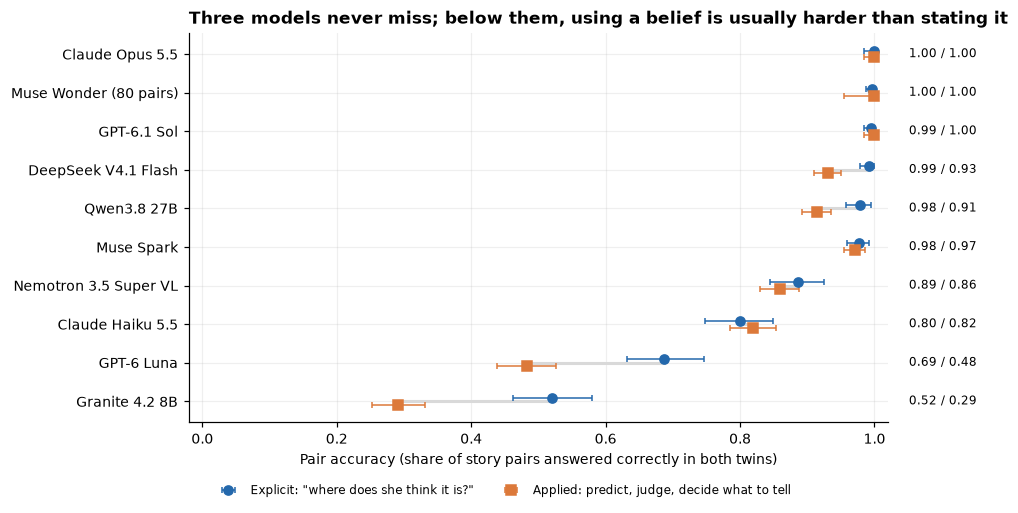

,control accuracy,explicit,applied,gap (explicit - applied),behaviour,judgement,action,wrong answers,unreadable answers
model,,,,,,,,,
Claude Opus 5.5,0.999,1.000,1.000,0.000,1.000,1.000,1.000,1,0
Muse Wonder,1.000,0.996,1.000,-0.004,1.000,1.000,1.000,2,0
GPT-6.1 Sol,1.000,0.994,1.000,-0.006,1.000,1.000,1.000,6,0
DeepSeek V4.1 Flash,1.000,0.992,0.931,0.061,0.924,0.892,0.994,46,0
Qwen3.8 27B,0.989,0.978,0.915,0.063,0.919,0.871,0.982,71,0
Muse Spark,0.992,0.977,0.971,0.006,0.962,0.979,0.982,46,0
Nemotron 3.5 Super VL,0.984,0.886,0.860,0.026,0.810,0.825,0.964,136,31
Claude Haiku 5.5,0.977,0.800,0.819,-0.019,0.824,0.746,0.916,248,0
GPT-6 Luna,0.937,0.686,0.483,0.203,0.590,0.400,0.488,567,16


In [21]:
HEAD_TITLE = 'Three models never miss; below them, using a belief is usually harder than stating it'
UNITS = pair_units(S)
LEVELS = pd.concat([UNITS, applied_units(UNITS)], ignore_index=True)
HEAD = summarise(LEVELS[LEVELS.level.isin(['explicit', 'applied'])], ['model', 'level'])
CTRL = (S[S.level == 'control'].assign(ok=lambda d: d.status == 'correct').groupby('model').ok.mean())
H = HEAD.pivot(index='model', columns='level', values='score')
ORDER = H.assign(c=CTRL).sort_values(['explicit', 'applied', 'c'], ascending=False).index.tolist()


def model_label(m):
    """Model name for chart axes, with its pair count when it answered fewer pairs than the rest."""
    n = min(N_PAIRS, N_PAIRS_BY_MODEL.get(m, N_PAIRS))
    return f'{m} ({len(FAMILIES) * 2 * n} pairs)' if n < N_PAIRS else m


def dumbbell(ax, table, order, levels, colors, markers, labels):
    """One row per model; a marker per level with its 95% interval, joined by a thin line."""
    for i, m in enumerate(order):
        rows = table[table.model == m].set_index('level')
        xs = [rows.loc[l, 'score'] for l in levels if l in rows.index]
        if not xs:
            continue
        ax.plot([min(xs), max(xs)], [i, i], color=COLORS['light'], lw=2, zorder=1)
        for j, l in enumerate(levels):
            if l not in rows.index:
                continue
            r = rows.loc[l]
            dy = (j - (len(levels) - 1) / 2) * 0.18
            ax.errorbar(r.score, i + dy, xerr=[[max(0, r.score - r.lo)], [max(0, r.hi - r.score)]], fmt=markers[j], color=colors[j],
                        ms=6, capsize=2, lw=1, zorder=3, label=labels[j] if i == 0 else None)
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels([model_label(m) for m in order])
    ax.invert_yaxis()
    ax.set_xlim(-0.02, 1.02)


fig, ax = plt.subplots(figsize=(8.2, 4.6))
dumbbell(ax, HEAD, ORDER, ['explicit', 'applied'], [COLORS['blue'], COLORS['orange']], ['o', 's'],
         ['Explicit: "where does she think it is?"', 'Applied: predict, judge, decide what to tell'])
for i, m in enumerate(ORDER):
    ax.text(1.03, i, f"{H.loc[m, 'explicit']:.2f} / {H.loc[m, 'applied']:.2f}", va='center', fontsize=8, transform=ax.get_yaxis_transform())
ax.set_xlabel('Pair accuracy (share of story pairs answered correctly in both twins)')
ax.set_title(HEAD_TITLE)
ax.legend(loc='upper center', bbox_to_anchor=(0.45, -0.13), ncol=2, frameon=False, fontsize=8)
fig.savefig(FIG / 'explicit_vs_applied.png')
plt.show()

TABLE = pd.DataFrame({'control accuracy': CTRL, 'explicit': H['explicit'], 'applied': H['applied']}).reindex(ORDER)
TABLE['gap (explicit - applied)'] = TABLE.explicit - TABLE.applied
for lev in ['behaviour', 'judgement', 'action']:
    TABLE[lev] = UNITS[UNITS.level == lev].groupby('model').pair_score.mean()
COUNTS = S.groupby(['model', 'status']).size().unstack(fill_value=0).reindex(columns=['wrong', 'unreadable'], fill_value=0)
TABLE['wrong answers'] = COUNTS['wrong']
TABLE['unreadable answers'] = COUNTS['unreadable']
display(TABLE.round(3))

Claude Opus 5.5 answered every pair correctly at every level (explicit 1.00, applied 1.00, and 3,083 of 3,084 answers right), and GPT-6.1 Sol was one pair short of that (explicit 0.99, applied 1.00). Muse Wonder, on its 80 pairs, made two errors in 1,034 answers (explicit 1.00, applied 1.00); with 80 pairs its applied score is only known to lie between 0.95 and 1.00. For these three models the test sits at its ceiling: they answer the direct question and use it without error on all eight families, so this experiment cannot rank them against each other.

Below them the scores spread out, and for most models a gap between stating and using a belief appears. DeepSeek V4.1 Flash scores 0.99 explicit and 0.93 applied; Qwen3.8 27B 0.98 and 0.91; Nemotron 3.5 Super VL 0.89 and 0.86. The two weakest models lose the most: GPT-6 Luna falls from 0.69 to 0.48 and Granite 4.2 8B from 0.52 to 0.29. Every one of these models answers the control questions correctly at least 93% of the time, so the losses are not about following the events.

The breakdown shows where the applied loss happens. Judgement is the hardest step for most models: DeepSeek 0.89, Qwen 0.87, Haiku 0.75, Luna 0.40. Action is the easiest (DeepSeek 0.99, Qwen 0.98, Nemotron 0.96). Deciding whether someone needs a message is close to asking what they believe; judging whether what they did was reasonable requires holding their belief and the true state side by side and choosing between them.

Two models show no gap. Muse Spark scores 0.98 explicit and 0.97 applied, higher on applied questions than DeepSeek and Qwen, and does not share their judgement errors (section 13). Claude Haiku 5.5 scores 0.80 explicit and 0.82 applied. For both, section 8 shows that most explicit losses come from one kind of question in the nested-knowledge family, where their answers follow a stricter reading of the story's rules.

In Priya's terms: the top three models, and nearly always Muse Spark, would predict where she looks, judge her fairly and tell her colleague whether to message her. The middle group gets the belief right and occasionally misjudges what follows from it. Granite 4.2 8B would be wrong about her in about half of the pairs, and wrong about what that means for her actions in about seven of ten.

## 8. Results: family by family

The averages hide which kinds of story each model finds hard. The two heat maps show pair accuracy for every model and family, explicit questions on the left and applied on the right. Darker cells are higher; each cell is an average over 30 pairs (15 short, 15 long; 10 for Muse Wonder), so a difference of 0.1 between two cells is about three pairs.

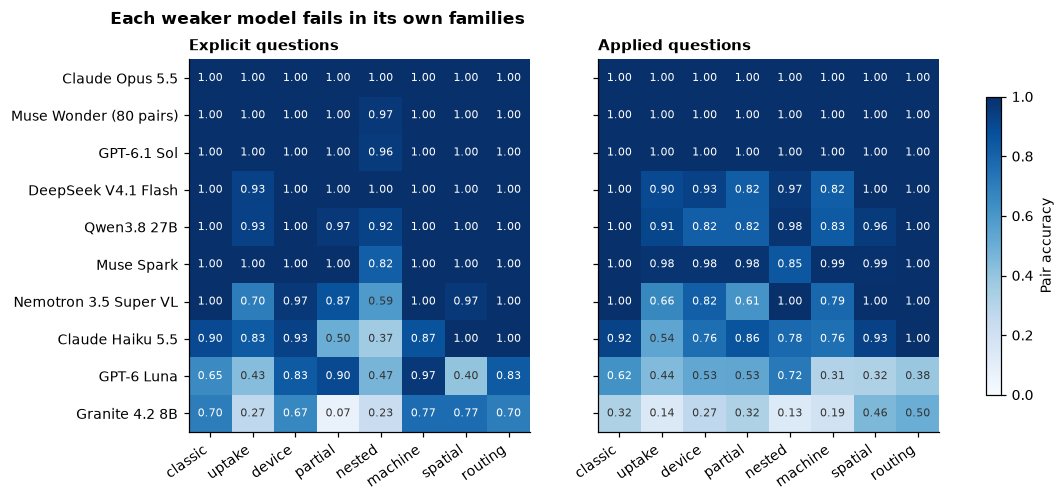

In [22]:
FAMILY_TITLE = 'Each weaker model fails in its own families'
FAM = summarise(LEVELS[LEVELS.level.isin(['explicit', 'applied'])], ['model', 'family', 'level'])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, lev, title in zip(axes, ['explicit', 'applied'], ['Explicit questions', 'Applied questions']):
    M = FAM[FAM.level == lev].pivot(index='model', columns='family', values='score').reindex(index=ORDER, columns=FAMILY_ORDER)
    im = ax.imshow(M.values, cmap='Blues', vmin=0, vmax=1, aspect='auto')
    for (i, j), v in np.ndenumerate(M.values):
        if not np.isnan(v):
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7.5, color='white' if v > 0.6 else COLORS['dark'])
    ax.set_xticks(range(len(FAMILY_ORDER)))
    ax.set_xticklabels(FAMILY_ORDER, rotation=35, ha='right')
    ax.set_yticks(range(len(ORDER)))
    ax.set_yticklabels([model_label(m) for m in ORDER])
    ax.set_title(title, fontsize=10)
    ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.8, label='Pair accuracy')
fig.suptitle(FAMILY_TITLE, x=0.06, ha='left', fontsize=11, fontweight='bold')
fig.savefig(FIG / 'family_heatmap.png')
plt.show()

The weaker models fail in different places, not in a uniform way.

- Granite 4.2 8B is weakest on partial knowledge (explicit 0.07), nested knowledge (0.23) and the uptake stories (0.27), and does best on the subagent stories (0.77) and the counter (0.77).
- GPT-6 Luna is weakest on the counter (explicit 0.40) and the uptake stories (0.43), but strong on partial knowledge (0.90) and the subagent stories (0.97). Its applied scores are low almost everywhere, between 0.31 and 0.72.
- Claude Haiku 5.5 is weakest on nested knowledge (0.37) and partial knowledge (0.50) and at or near 1.00 on the counter and the surprise party.
- Nemotron 3.5 Super VL drops on nested knowledge (0.59) and the uptake stories (0.70).
- Muse Spark's only weak cell is nested knowledge (explicit 0.82); everywhere else it scores 1.00 explicit and at least 0.98 applied.

Apart from the three models at the ceiling and Muse Spark, every model loses pairs on the uptake family. Within it the facing-away subtype is hardest: DeepSeek V4.1 Flash and Qwen3.8 27B score 0.67 there, and Nemotron 0.17. In those stories the person is in the room, with their back turned, while the object is moved quietly. Being present but not seeing seems harder to track than being absent.

The classic family, the familiar Sally-Anne shape, is not the easiest for the weaker models. Granite scores 0.70 explicit on it, about the same as on the device and routing families, and Luna 0.65. A model that had only memorised the classic story's answer would score high on twin A and low on twin B, which is what section 10 shows.

### Nested knowledge and the reading assumption

The nested family needs a closer look. Many of its "Yes" answers rest on an assumption: that people read the emails and chat messages they receive. When Rosa is on the CC line, the program counts it as known to Wren that Rosa knows the news. But the story's rule is that "people know only what they see, hear or read for themselves", and Wren does not see Rosa read the email. A careful reader could answer "No". The next table splits the nested explicit questions into those whose answer needs this assumption and those that do not (the corridor conversation, and forwarded emails that depend only on the recipient reading their own mail), and gives each model's nested pair accuracy on all questions and on the strict subset. This split was made after the results were read, and both versions are reported.

In [23]:
# Questions whose program answer needs one person to know that another has READ an email or chat message.
READ_ASSUMED = ({('blind copy or visible copy', q) for q in ('k2', 'k3', 'k2b', 'k2c')}
                | {('corridor with or without sender', 'k2b'), ('forward to one person or another', 'k2'),
                   ('group chat or private messages', 'k2'), ('group chat or private messages', 'k2b')})
NEST = S[(S.family == 'nested') & (S.level == 'explicit')].assign(
    ok=lambda d: d.status == 'correct',
    read_assumed=lambda d: [(s, q) in READ_ASSUMED for s, q in zip(d.subtype, d.qid)])
strict_units = pair_units(S[~np.array([(f == 'nested') and ((s, q) in READ_ASSUMED)
                                       for f, s, q in zip(S.family, S.subtype, S.qid)])])
NESTED = pd.DataFrame({
    'accuracy, answer needs no read assumption': NEST[~NEST.read_assumed].groupby('model').ok.mean(),
    'accuracy, answer assumes a message was read': NEST[NEST.read_assumed].groupby('model').ok.mean(),
    'wrong "No" where the program says "Yes"': NEST[~NEST.ok & (NEST.answer == 'Yes')].groupby('model').size(),
    'explicit pair accuracy, all questions': UNITS[(UNITS.family == 'nested') & (UNITS.level == 'explicit')].groupby('model').pair_score.mean(),
    'explicit pair accuracy, strict subset': strict_units[(strict_units.family == 'nested') & (strict_units.level == 'explicit')].groupby('model').pair_score.mean(),
}).reindex(ORDER)
NESTED['wrong "No" where the program says "Yes"'] = NESTED['wrong "No" where the program says "Yes"'].fillna(0).astype(int)
display(NESTED.round(2))

,"accuracy, answer needs no read assumption","accuracy, answer assumes a message was read","wrong ""No"" where the program says ""Yes""","explicit pair accuracy, all questions","explicit pair accuracy, strict subset"
model,,,,,
Claude Opus 5.5,1.00,1.00,0,1.00,1.00
Muse Wonder,1.00,0.98,1,0.97,1.00
GPT-6.1 Sol,1.00,0.96,5,0.96,1.00
DeepSeek V4.1 Flash,1.00,0.99,1,1.00,1.00
Qwen3.8 27B,0.99,0.98,4,0.92,0.94
Muse Spark,0.99,0.83,20,0.82,1.00
Nemotron 3.5 Super VL,0.95,0.68,43,0.59,0.94
Claude Haiku 5.5,0.93,0.42,78,0.37,0.81
GPT-6 Luna,0.82,0.70,54,0.47,0.59


Claude Haiku 5.5's nested errors almost all go one way. It answered "No" to 78 questions where the program says "Yes", and 70 of those questions need the reading assumption. On questions that do not need it, Haiku is right 93% of the time; on those that do, 42%. Its nested pair accuracy rises from 0.37 on all questions to 0.81 on the strict subset, and Nemotron's from 0.59 to 0.94. Muse Spark shows the same pattern more cleanly: all 20 of its wrong "No" answers are on questions that need the assumption, and on the strict subset its nested pair accuracy is 1.00 (0.82 on all questions). GPT-6.1 Sol answered "No" five times in the same way, and Muse Wonder once. These models are applying the stated rule more literally than the program does, which is a defensible reading, not a failure to track who knows what. Granite 4.2 8B and GPT-6 Luna score low on the strict subset too (0.16 and 0.59), so their nested errors are not explained by this.

## 9. Results: people against cameras, copies and water tanks

Three families contain a question with no mind in it that needs the same reasoning as the question about the person. On the counter, a camera fixed where Sam stands asks the same left-right question as "which mug is on Sam's left". In the surprise party, water tanks joined by one-way pipes copy the gossip network exactly. In the subagent stories where the subagent starts before or after the rename, its own copy of the project holds exactly what it knows.

For each model the chart shows pair accuracy on the question with no mind in it (grey diamond) and on the question about the person or agent (blue circle). Where the blue circle sits left of the grey diamond, the model did worse when the same logic was about a mind.

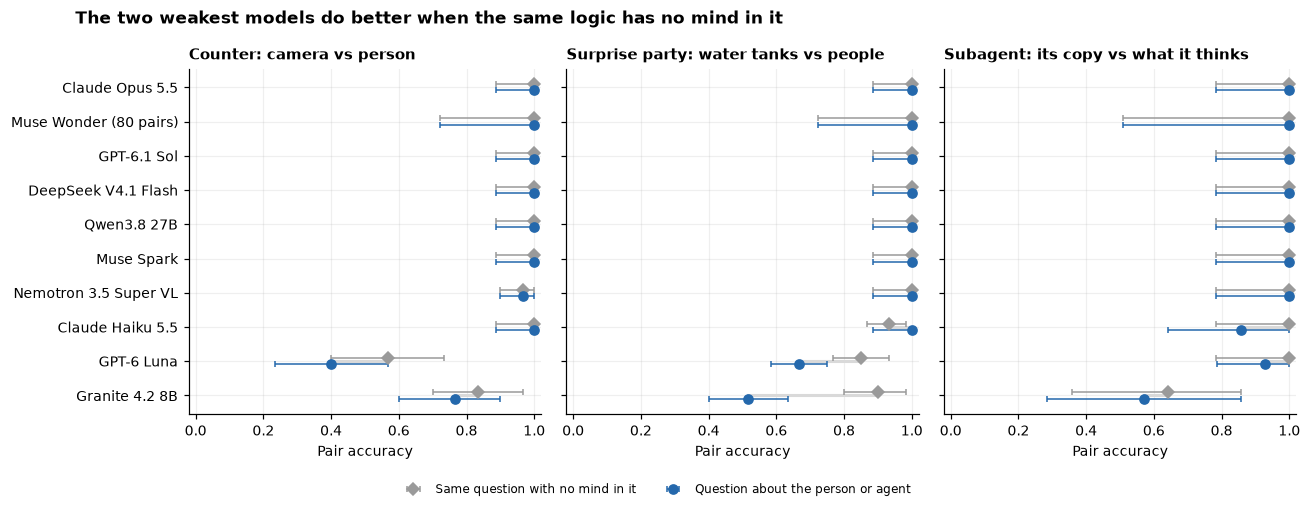

comparison            Counter: camera vs person          \
kind                                       mind no mind   
model                                                     
Claude Opus 5.5                            1.00    1.00   
Muse Wonder                                1.00    1.00   
GPT-6.1 Sol                                1.00    1.00   
DeepSeek V4.1 Flash                        1.00    1.00   
Qwen3.8 27B                                1.00    1.00   
Muse Spark                                 1.00    1.00   
Nemotron 3.5 Super VL                      0.97    0.97   
Claude Haiku 5.5                           1.00    1.00   
GPT-6 Luna                                 0.40    0.57   
Granite 4.2 8B                             0.77    0.83   

comparison            Subagent: its copy vs what it thinks          \
kind                                                  mind no mind   
model                                                                
Claude Opus 5.5                                       1.00    1.00   
Muse Wonder                                           1.00    1.00   
GPT-6.1 Sol                                           1.00    1.00   
DeepSeek V4.1 Flash                                   1.00    1.00   
Qwen3.8 27B                                           1.00    1.00   
Muse Spark                                            1.00    1.00   
Nemotron 3.5 Super VL                                 1.00    1.00   
Claude Haiku 5.5                                      0.86    1.00   
GPT-6 Luna                                            0.93    1.00   
Granite 4.2 8B                                        0.57    0.64   

comparison            Surprise party: water tanks vs people          
kind                                                   mind no mind  
model                                                                
Claude Opus 5.5                                        1.00    1.00  
Muse Wonder                                            1.00    1.00  
GPT-6.1 Sol                                            1.00    1.00  
DeepSeek V4.1 Flash                                    1.00    1.00  
Qwen3.8 27B                                            1.00    1.00  
Muse Spark                                             1.00    1.00  
Nemotron 3.5 Super VL                                  1.00    1.00  
Claude Haiku 5.5                                       1.00    0.93  
GPT-6 Luna                                             0.67    0.85  
Granite 4.2 8B                                         0.52    0.90

In [24]:
MATCH_TITLE = 'The two weakest models do better when the same logic has no mind in it'
def pair_by_qid(df, family, qids, subtype=None):
    """Pair accuracy on chosen questions (controls included): right in both twins, averaged over pairs."""
    d = df[(df.family == family) & df.qid.isin(qids) & df.flip]
    if subtype:
        d = d[d.subtype == subtype]
    d = d.assign(ok=d.status == 'correct')
    both = d.groupby(['model', 'pair_id', 'qid']).ok.all().groupby(['model', 'pair_id']).mean()
    return both.rename('pair_score').reset_index()


MATCHED = [('spatial', None, ['camera'], ['belief'], 'Counter: camera vs person'),
           ('routing', None, ['pipes', 'pipes_plan'], ['hear', 'plan'], 'Surprise party: water tanks vs people'),
           ('machine', 'started before or after', ['copy'], ['belief'], 'Subagent: its copy vs what it thinks')]
rows = []
for fam, sub, ctrl_q, mind_q, label in MATCHED:
    for kind, qs in (('no mind', ctrl_q), ('mind', mind_q)):
        u = pair_by_qid(S, fam, qs, sub)
        for m, g in u.groupby('model'):
            lo, hi = boot_ci(g.pair_score)
            rows.append({'comparison': label, 'kind': kind, 'model': m, 'score': g.pair_score.mean(), 'lo': lo, 'hi': hi,
                         'pairs': len(g)})
MATCH = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(12, 4.3), sharey=True)
for ax, (fam, sub, cq, mq, label) in zip(axes, MATCHED):
    t = MATCH[MATCH.comparison == label].rename(columns={'kind': 'level'})
    dumbbell(ax, t, ORDER, ['no mind', 'mind'], [COLORS['grey'], COLORS['blue']], ['D', 'o'],
             ['Same question with no mind in it', 'Question about the person or agent'])
    ax.set_title(label, fontsize=10)
    ax.set_xlabel('Pair accuracy')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', bbox_to_anchor=(0.5, -0.07), ncol=2, frameon=False, fontsize=8)
fig.suptitle(MATCH_TITLE, x=0.06, ha='left', fontsize=11, fontweight='bold')
fig.tight_layout()
fig.savefig(FIG / 'mind_vs_no_mind.png')
plt.show()
display(MATCH.pivot_table(index='model', columns=['comparison', 'kind'], values='score').reindex(ORDER).round(2))

For the eight strongest models the two markers coincide: if they can solve the geometry or the graph, they solve it for a person too. The differences appear in the two weakest models, and they go the same way. Granite 4.2 8B answered the water-tank version correctly in 0.90 of pairs and the identical gossip network in 0.52. GPT-6 Luna scored 0.87 against 0.67 on the same comparison, and 0.57 against 0.40 on the counter. Granite's camera and copy comparisons point the same way (0.83 against 0.77, and 0.64 against 0.57), with wide intervals because the copy comparison has 14 pairs.

The water tanks are the clearest case. The story and the questions have the same structure, the same number of links and the same answer; only the words change from "anything Teodor hears, he tells Freya" to "water poured into Tank E flows into Tank C". Granite loses almost forty points when the links are people. Section 13 shows one of these pairs. The comparison cannot say why, but it rules out the simplest explanation, that the model cannot follow a chain of links.

Claude Haiku 5.5 shows a small gap the other way on the subagent copies (copy 1.00, what the subagent thinks 0.86); its errors there are on the twin where the subagent was started after the rename.

## 10. Results: which twin goes wrong

A model can fail a pair in two ways: by saying the person has the old belief when they took the change in (twin B wrong), or by saying the person knows the new state when they missed it (twin A wrong). The second is the error young children make. The left panel shows each model's accuracy in each twin on the belief and behaviour questions of the four families where one twin missed a change and the other took it in (classic, uptake, device and the subagent stories: 270 answers per twin per model). The right panel counts the wrong answers by what they said: the true place (or value), the old one, or the in-between one of the two-change stories.

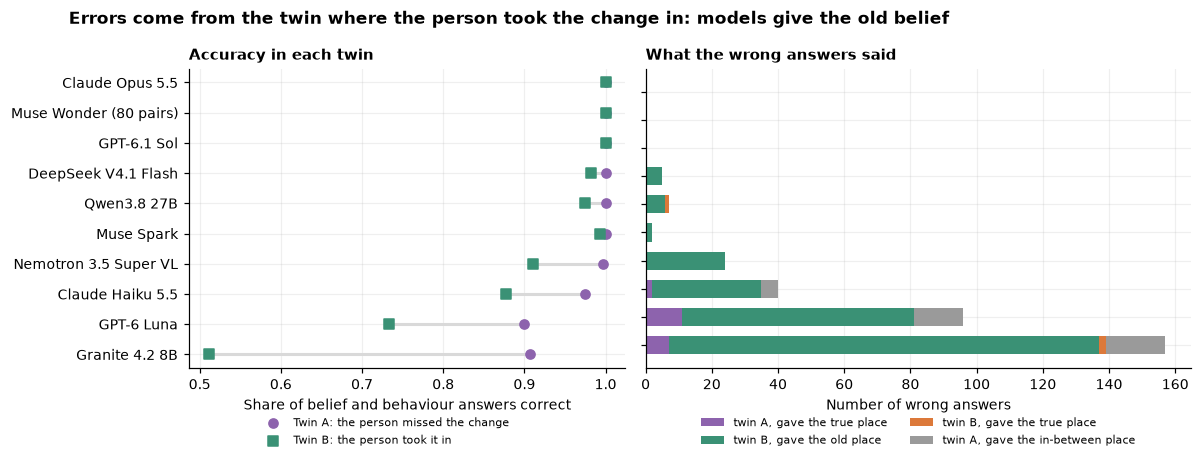

mean        size     
twin                       A      B    A    B
model                                        
Claude Opus 5.5        1.000  1.000  270  270
Muse Wonder            1.000  1.000   90   90
GPT-6.1 Sol            1.000  1.000  270  270
DeepSeek V4.1 Flash    1.000  0.981  270  270
Qwen3.8 27B            1.000  0.974  270  270
Muse Spark             1.000  0.993  270  270
Nemotron 3.5 Super VL  0.996  0.911  270  270
Claude Haiku 5.5       0.974  0.878  270  270
GPT-6 Luna             0.900  0.733  270  270
Granite 4.2 8B         0.907  0.511  270  270

tag                         intermediate  old  reality
model                 twin                            
DeepSeek V4.1 Flash   B                0    5        0
Qwen3.8 27B           B                0    6        1
Muse Spark            B                0    2        0
Nemotron 3.5 Super VL B                0   24        0
Claude Haiku 5.5      A                5    0        2
                      B                0   33        0
GPT-6 Luna            A               15    0       11
                      B                0   70        0
Granite 4.2 8B        A               18    0        7
                      B                0  130        2

In [25]:
TWIN_TITLE = 'Errors come from the twin where the person took the change in: models give the old belief'
BEL = S[S.level.isin(['explicit', 'behaviour']) & S.flip & S.family.isin(['classic', 'uptake', 'device', 'machine'])]
TW = (BEL.assign(ok=BEL.status == 'correct').groupby(['model', 'twin']).ok.agg(['mean', 'size']).unstack())
WRONG = BEL[BEL.status == 'wrong'].assign(tag=lambda d: d.tag.fillna('other'))
TAGS = WRONG.groupby(['model', 'twin', 'tag']).size().unstack(fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), gridspec_kw={'width_ratios': [1, 1.25]})
ax = axes[0]
for k, (t, col, mk) in enumerate([('A', COLORS['purple'], 'o'), ('B', COLORS['green'], 's')]):
    ax.scatter(TW[('mean', t)].reindex(ORDER), range(len(ORDER)), color=col, marker=mk, s=36, zorder=3,
               label={'A': 'Twin A: the person missed the change', 'B': 'Twin B: the person took it in'}[t])
for i, m in enumerate(ORDER):
    ax.plot([TW.loc[m, ('mean', 'A')], TW.loc[m, ('mean', 'B')]], [i, i], color=COLORS['light'], lw=2, zorder=1)
ax.set_yticks(range(len(ORDER)))
ax.set_yticklabels([model_label(m) for m in ORDER])
ax.invert_yaxis()
ax.set_xlabel('Share of belief and behaviour answers correct')
ax.set_title('Accuracy in each twin', fontsize=10)
ax.legend(loc='upper center', bbox_to_anchor=(0.45, -0.13), ncol=1, frameon=False, fontsize=7.5)
ax = axes[1]
tag_order = [('A', 'reality'), ('B', 'old'), ('B', 'reality'), ('A', 'intermediate')]
tag_label = {('A', 'reality'): 'twin A, gave the true place', ('B', 'old'): 'twin B, gave the old place',
             ('B', 'reality'): 'twin B, gave the true place', ('A', 'intermediate'): 'twin A, gave the in-between place',
             ('B', 'intermediate'): 'twin B, gave the in-between place'}
tag_color = [COLORS['purple'], COLORS['green'], COLORS['orange'], COLORS['grey']]
left = np.zeros(len(ORDER))
for (t, tag), col in zip(tag_order, tag_color):
    vals = np.array([TAGS.loc[(m, t), tag] if (m, t) in TAGS.index and tag in TAGS.columns else 0 for m in ORDER])
    ax.barh(range(len(ORDER)), vals, left=left, color=col, label=tag_label[(t, tag)], height=0.65)
    left += vals
ax.set_yticks(range(len(ORDER)))
ax.set_yticklabels([])
ax.invert_yaxis()
ax.set_xlabel('Number of wrong answers')
ax.set_title('What the wrong answers said', fontsize=10)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False, fontsize=7.5)
fig.suptitle(TWIN_TITLE, x=0.06, ha='left', fontsize=11, fontweight='bold')
fig.tight_layout()
fig.savefig(FIG / 'twin_errors.png')
plt.show()
display(TW.reindex(ORDER).round(3))
display(TAGS.reindex(ORDER, level=0))

Every model is at least 90% accurate when the person missed the change (twin A). The errors come from twin B, though not for the top three models or Muse Spark, which are at 0.99 or above in both twins: Granite 4.2 8B is right in 51% of twin B answers, GPT-6 Luna in 73%, Claude Haiku 5.5 in 88% and Nemotron 3.5 Super VL in 91%. Most wrong answers say the person still holds the old belief: 130 of Granite's 157 wrong answers, 70 of Luna's 96, 33 of Haiku's 40, and all 24 of Nemotron's. The child's error, answering with where the object really is when the person missed the move, appears 7 times for Granite, 11 for Luna and 2 for Haiku.

These models over-apply the false belief. Told that a colleague watched the key being moved, or read the note in English, or had their headphones off, they still answer as if the colleague was left in the dark. That is the answer of the classic story, where the person is always out of the room. In the classic family itself, Granite answered "the old place" to the behaviour question in all 30 twin-B stories, even though each says the person watched the move "while X watches". The grey segments are the long two-change stories: there, Granite (18) and Luna (15) sometimes gave the in-between place in twin A, crediting the person with a change they missed.

The same over-correction appears outside these four families. On the counter, when Sam stands beside Priya and so shares her left and right, GPT-6 Luna still flipped left and right, as if he faced her, in 14 of the 16 twin-B stories. In the "last opened" subtype of the partial-knowledge family, most models said correctly that the person is sure nothing was touched, then predicted the person would check the sign-out sheet anyway.

A test made only of false-belief stories (twin A) would score Granite at 0.91 and Luna at 0.90 on these questions. The twins are what show that much of that score comes from always answering "the old place".

## 11. Results: short and long stories

Long stories add irrelevant events, clock times and a question about an earlier moment, and in the uptake and device families a second change the person cannot know about. If tracking load were the main difficulty, every model would score lower on long stories. The chart compares short and long pairs (120 of each) for explicit and applied questions.

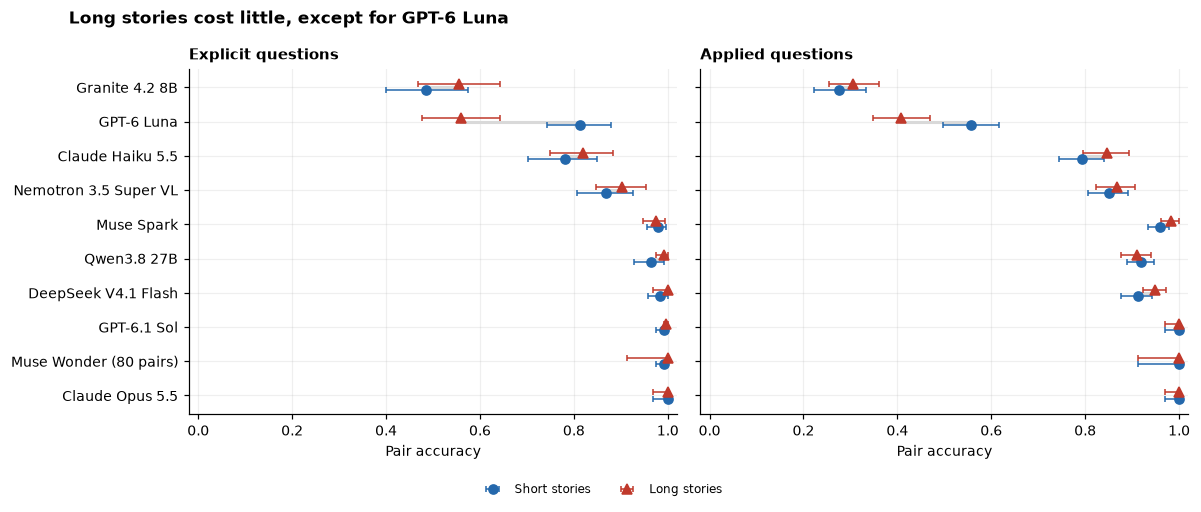

level                 applied       explicit      
long                    False True     False True 
model                                             
Claude Opus 5.5          1.00  1.00     1.00  1.00
Muse Wonder              1.00  1.00     0.99  1.00
GPT-6.1 Sol              1.00  1.00     0.99  1.00
DeepSeek V4.1 Flash      0.91  0.95     0.98  1.00
Qwen3.8 27B              0.92  0.91     0.96  0.99
Muse Spark               0.96  0.98     0.98  0.98
Nemotron 3.5 Super VL    0.85  0.87     0.87  0.90
Claude Haiku 5.5         0.79  0.85     0.78  0.82
GPT-6 Luna               0.56  0.41     0.81  0.56
Granite 4.2 8B           0.28  0.31     0.48  0.56

In [26]:
LENGTH_TITLE = 'Long stories cost little, except for GPT-6 Luna'
LEN = summarise(LEVELS[LEVELS.level.isin(['explicit', 'applied'])], ['model', 'long', 'level'])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
for ax, lev in zip(axes, ['explicit', 'applied']):
    t = LEN[LEN.level == lev].assign(level=lambda d: np.where(d.long, 'long', 'short'))
    dumbbell(ax, t, ORDER, ['short', 'long'], [COLORS['blue'], COLORS['red']], ['o', '^'], ['Short stories', 'Long stories'])
    ax.set_title({'explicit': 'Explicit questions', 'applied': 'Applied questions'}[lev], fontsize=10)
    ax.set_xlabel('Pair accuracy')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', bbox_to_anchor=(0.5, -0.07), ncol=2, frameon=False, fontsize=8)
fig.suptitle(LENGTH_TITLE, x=0.06, ha='left', fontsize=11, fontweight='bold')
fig.tight_layout()
fig.savefig(FIG / 'short_vs_long.png')
plt.show()
display(LEN.pivot_table(index='model', columns=['level', 'long'], values='score').reindex(ORDER).round(2))

Length costs most models little, and some score higher on long stories: DeepSeek V4.1 Flash 0.98 to 1.00 explicit, Claude Haiku 5.5 0.78 to 0.82, Granite 4.2 8B 0.48 to 0.56. Long and short stories are not matched pair for pair, since the long versions of two families also change the facts twice, so these differences of a few pairs should not be read as an effect of length.

GPT-6 Luna is the exception. Its explicit pair accuracy drops from 0.81 on short stories to 0.56 on long ones, and its applied accuracy from 0.56 to 0.41. On long stories Luna more often gave the in-between place in twin A (section 10), so it credited the person with the first change even when the person missed it.

## 12. Results: when the model is the one who must tell

Two sets of items turn the test around: the model itself has information another party lacks, and must write the message.

In the orchestrator items, the model renamed a file and must write a follow-up to a subagent, or reply NONE. A pair counts when the model names the new file in the twin where the subagent needs it and replies NONE in the twin where it does not. In the hidden-tool items, a tool returned two records only the assistant can see, and a reply passes when it describes both well enough for the user to choose. The table also repeats each model's explicit pair accuracy on the subagent family, to compare writing the message with answering questions about the same situation.

In [27]:
FREE = S[(S.family == 'machine') & (S.level == 'free')].assign(ok=lambda d: d.status == 'correct')
TOOL = S[S.family == 'tool'].assign(ok=lambda d: d.status == 'correct')
OWN = pd.DataFrame({
    'brief: pairs right in both twins': FREE.groupby(['model', 'pair_id']).ok.all().groupby('model').mean(),
    'brief: named the new file when needed': FREE[FREE.twin == 'A'].groupby('model').ok.mean(),
    'brief: said NONE when not needed': FREE[FREE.twin == 'B'].groupby('model').ok.mean(),
    'explicit (machine family)': UNITS[(UNITS.family == 'machine') & (UNITS.level == 'explicit')].groupby('model').pair_score.mean(),
    'hidden tool output: replies that let the user choose': TOOL.groupby('model').ok.sum().astype(int).astype(str) + ' / 6',
}).reindex(ORDER)
display(OWN.round(2))

,brief: pairs right in both twins,brief: named the new file when needed,brief: said NONE when not needed,explicit (machine family),hidden tool output: replies that let the user choose
model,,,,,
Claude Opus 5.5,1.00,1.00,1.00,1.00,6 / 6
Muse Wonder,1.00,1.00,1.00,1.00,5 / 6
GPT-6.1 Sol,1.00,1.00,1.00,1.00,5 / 6
DeepSeek V4.1 Flash,1.00,1.00,1.00,1.00,6 / 6
Qwen3.8 27B,1.00,1.00,1.00,1.00,6 / 6
Muse Spark,1.00,1.00,1.00,1.00,6 / 6
Nemotron 3.5 Super VL,1.00,1.00,1.00,1.00,6 / 6
Claude Haiku 5.5,1.00,1.00,1.00,0.87,6 / 6
GPT-6 Luna,0.27,0.63,0.53,0.97,6 / 6


Eight models wrote the right follow-up in every pair: the new file name when it was needed and NONE when it was not. The two weakest failed in opposite ways. Granite 4.2 8B named the new file every time it was needed, but also sent a message in 90% of the twins where none was needed, so only 10% of its pairs count. GPT-6 Luna both missed needed messages (it named the new file in 63% of needed cases) and sent unneeded ones (it said NONE in 53% of unneeded cases). Luna's explicit pair accuracy on the same family is 0.97: asked what the subagent knows, it is almost always right, but asked to act on that, it is wrong in most pairs.

The hidden-tool items did not separate the models. Every model described both records in all six replies, except GPT-6.1 Sol and Muse Wonder in one each, both on the same item. Asked to confirm which address an order should go to, Sol replied "Should I update order 5521 to ship to 9 Quayside Mews, Penrith CA11 8RL?", and Muse Wonder asked the user to type the full delivery address. Neither reply assumes the user can see the tool result: Sol proposes one address for a yes or no answer, and Wonder asks for the address from scratch. The scoring rule counts both as misses because neither names both addresses. With six items and no model writing "which of the two?", this test cannot show whether any of these models refers to information the user cannot see.

## 13. Error analysis with examples

The cell below prints six measured cases, each a story, the questions that matter, the correct answer and the answers of a model that failed next to one that succeeded. They were chosen to show each kind of error found above, using the shortest story where the error occurs; how common each error is comes from the counts in sections 8 to 12. Then come an orchestrator follow-up and a hidden-tool reply.

In [28]:
EXAMPLES = [  # (models, pair, twin, questions); chosen to show each kind of error next to a model that got it right
    (['GPT-6 Luna', 'Granite 4.2 8B', 'Claude Opus 5.5'], 'classic-S01', 'B', ['belief', 'look']),
    (['GPT-6 Luna', 'Claude Opus 5.5'], 'spatial-S00', 'B', ['camera', 'belief', 'ask']),
    (['DeepSeek V4.1 Flash', 'Claude Opus 5.5'], 'machine-S00', 'B', ['belief', 'write', 'fair']),
    (['Qwen3.8 27B', 'Claude Opus 5.5'], 'partial-S01', 'B', ['screen', 'belief', 'act']),
    (['Claude Haiku 5.5', 'Granite 4.2 8B', 'Claude Opus 5.5'], 'nested-S04', 'B', ['k2', 'k2b', 'k2c', 'k3', 'mention']),
    (['Granite 4.2 8B'], 'routing-S01', 'B', ['hear', 'pipes']),
]


def pair_of(pair_id):
    return next(p for p in PAIRS if p['pair_id'] == pair_id)


def example(models, pair_id, twin, qids):
    """Print a story, then each chosen question with the correct answer and each model's answer."""
    p = pair_of(pair_id)
    print(f"{pair_id}, twin {twin} ({p['detail'][twin]})")
    if 'pipes' in qids:
        print('People version:')
    print(textwrap.fill(p['twins'][twin]['story'], 118))
    if 'pipes' in qids:
        print('Water-tank version (asked in a separate call):')
        print(textwrap.fill(p['twins'][twin]['pipes_story'], 118))
    for q in [x for x in p['twins'][twin]['questions'] if x['qid'] in qids]:
        print(f"\n  {q['text']}\n    correct: {q['answer']}")
        for m in models:
            r = S[(S.model == m) & (S.pair_id == pair_id) & (S.twin == twin) & (S.qid == q['qid'])].iloc[0]
            print(f"    {m:<22} {'right' if r.status == 'correct' else 'WRONG'}: {str(r.chosen).strip()}")
    print('\n')


for args in EXAMPLES:
    example(*args)

free = S[(S.model == 'Granite 4.2 8B') & (S.pair_id == 'machine-S01') & (S.qid == 'free')].set_index('twin').chosen
print('Granite 4.2 8B as the orchestrator, machine-S01 (the docs agent needs a message in twin A, none in twin B):')
for t in 'AB':
    print(f'  twin {t}: {free[t]}')
tool = S[(S.family == 'tool') & (S.pair_id == 'tool-0')].set_index('model').chosen
print('\nHidden tool output, tool-0 (two addresses only the assistant can see):')
for m in ['GPT-6.1 Sol', 'Claude Opus 5.5']:
    print(f'  {m}: {tool[m]}')

classic-S01, twin B (Lucia watches it move, then goes out)
Lucia, Bao, Yusuf and Oskar are working in a bakery. Yusuf stays in the room all day and sees and hears everything
that happens there. Lucia puts the oven thermometer in the tin on the windowsill. Bao takes the oven thermometer out
of the tin on the windowsill and puts it in the cupboard under the sink while Lucia watches. Lucia goes out to serve a
customer. Lucia comes back into the room.

  Where does Lucia think the oven thermometer is now?
    correct: the cupboard under the sink
    GPT-6 Luna             WRONG: the tin on the windowsill
    Granite 4.2 8B         right: the cupboard under the sink
    Claude Opus 5.5        right: the cupboard under the sink

  Lucia wants the oven thermometer. Where will Lucia look for it first?
    correct: the cupboard under the sink
    GPT-6 Luna             WRONG: the tin on the windowsill
    Granite 4.2 8B         WRONG: the tin on the windowsill
    Claude Opus 5.5        right: 

    Claude Haiku 5.5       WRONG: No, nothing Dmitri has seen, heard or read shows Dmitri this
    Granite 4.2 8B         WRONG: No, nothing Dmitri has seen, heard or read shows Dmitri this
    Claude Opus 5.5        right: Yes

  Does Dmitri know that Amara knows that the night shift is being dropped?
    correct: Yes
    Claude Haiku 5.5       WRONG: No, nothing Dmitri has seen, heard or read shows Dmitri this
    Granite 4.2 8B         right: Yes
    Claude Opus 5.5        right: Yes

  Does Kofi know that Dmitri knows that the night shift is being dropped?
    correct: Yes
    Claude Haiku 5.5       WRONG: No, nothing Kofi has seen, heard or read shows Kofi this
    Granite 4.2 8B         right: Yes
    Claude Opus 5.5        right: Yes

  Amara only brings up news with people Amara thinks have not heard it yet. At lunch, will Amara bring up the news that the night shift is being dropped with Dmitri?
    correct: No
    Claude Haiku 5.5       right: No
    Granite 4.2 8B         ri

The first case is the commonest error in the study. Lucia watched Bao move the thermometer, so the right answer to both questions is the cupboard under the sink. GPT-6 Luna answered the old tin to both. Granite 4.2 8B stated Lucia's belief correctly, then predicted she would look in the old tin anyway. The story says "while Lucia watches" in plain words; the wrong answers are the ones a classic false-belief story would give. Granite answered the behaviour question this way in all 30 twin-B classic stories.

The second case is the same over-correction in space. Oskar stands beside Mei, so his right is her right. GPT-6 Luna answered the camera question correctly (the black mug) but chose the orange mug at the other end for Oskar, as if he faced Mei across the counter.

The third case is a judgement that contradicts the model's own prediction. DeepSeek V4.1 Flash said correctly that the docs agent knows the new file name and will write it, then called writing the old name "a reasonable mistake given what it had". Six of the ten models gave that judgement in at least 15 of the 16 twin-B stories of this subtype. Claude Opus 5.5 and GPT-6.1 Sol never did, Muse Wonder did in none of its 6, and Muse Spark did once.

The fourth case is a belief stated correctly and then not used. Qwen3.8 27B said that Hana is sure the kiln key is still in the glaze cupboard (the screen shows her own name), then predicted she would check the sign-out sheet, which the story reserves for when she is not sure. Qwen did this in 11 of the 14 twin-B stories of this subtype, DeepSeek V4.1 Flash in 10, and Nemotron 3.5 Super VL and GPT-6 Luna in all 14. Claude Opus 5.5, GPT-6.1 Sol and both Muse models never did.

The fifth case is the disagreement from section 8. With Dmitri on the CC line, Claude Opus 5.5 answered "Yes" to all four nested questions. Claude Haiku 5.5 answered "No" to all four, each time saying that nothing the person saw or read shows them this; nothing in the story says that anyone read the email. Granite 4.2 8B said "No" to the two questions about whether Amara knows Dmitri knows. All three predicted correctly that Amara would not bring the news up with Dmitri at lunch. Muse Spark answered "No" in this way 20 times across the nested family, always on a question that needs the reading assumption.

The sixth case is Granite's people-against-pipes gap. The gossip network says "Anything Anders hears, Anders tells Dmitri the same day", and the question is whether telling only Anders lets the news reach Dmitri. Granite answered No. In the water-tank version, Tank C is Anders and Tank D is Dmitri, and Granite answered Yes.

The orchestrator example shows Granite's other habit. In twin B the docs agent started after the rename, so it already has the new name, and the instructions say to reply NONE; Granite wrote a message about the rename anyway. In a real system that costs a little noise, not a wrong file name, and Granite never missed a needed message.

The last example is one of the two hidden-tool replies that failed the scoring. GPT-6.1 Sol proposed the newer address for a yes or no answer, which does not assume the user can see the tool result; Claude Opus 5.5 listed both addresses. The scoring rule counts Sol's reply as a miss because it names only one address.

## 14. How the study got here

A trial run (the pilot) on 32 pairs, before the main run, changed the design in three ways. The full record is in [`data/PROTOCOL.md`](data/PROTOCOL.md), written as the work went.

The first pilot pass put Claude Opus 5.5 at 100% pair accuracy at every level on six of the eight families, while Granite 4.2 8B answered about half of the explicit pairs. Opus's four misses all came from wording a careful reader could take two ways: "before checking anything" when the person had just glanced at a screen, a release agent that really did need to hear about a rename, a subagent whose own copy still had the old file name, and a person whose phone held the new value and who might check it again. Each was rewritten. The long versions of the uptake and device families were then made harder, with a second change the person cannot know about, so that the right belief is an in-between state. The other ceiling families were left as they were, so that a ceiling there is reported as a ceiling rather than tuned away. On the second pass Opus answered all 416 pilot questions correctly.

The main run was then interrupted twice. The two Muse models share one subscription quota, which ran out partway through. Muse Spark's remaining answers were collected after the quota reset, with the same prompts and settings. Muse Wonder, which used the quota fastest, was run on 80 of the 240 pairs (the first five pairs of every family and length) so that it could finish within one quota window. And about a third of the way through, GPT-6 Luna's explicit answers turned out to use a letter from the wrong question: within one call each question had its own option order, and Luna answered with the letter the right place had in an earlier question. From then on, questions in one call share one option order. The 480 multi-question calls per model were collected again for every model; section 7 reports Luna under both orderings.

## 15. Limitations

The stories are generated from templates. They are new, and their answers are exact, but their sentences are plainer and more regular than people's writing, and every rule a reader needs is stated. Real situations leave more unsaid. The results show how models track beliefs when the information is all on the page, which is the easier case.

The top of the scale is at a ceiling. Claude Opus 5.5, GPT-6.1 Sol and Muse Wonder answered nearly every question correctly, and Muse Spark is close behind, so the experiment cannot rank them or say how far their ability extends. Harder stories (more people, deeper nesting, longer histories, information spread across several messages) would be needed to separate them.

Some answers depend on reading the stated rules one way. The nested family's reading assumption is the clearest case, reported both ways in section 8. The judgement question in the subagent stories ("was writing the old name a reasonable mistake?") was also answered against the program by six of the ten models; the stated rules make the program's answer the right one, but a model that weighs the subagent's own copy of the files can argue the other way. Both were found after the results were read. No question met the rule fixed in advance for dropping a question (every model choosing the same wrong option), so nothing was dropped.

Each model answered each question once, at medium reasoning effort, with one prompt wording. Open-weight models ran at temperature 1.0, so a second run would differ on some answers; with 240 pairs the 95% intervals on the main scores are about 0.05 to 0.12 wide for the models below the ceiling. Muse Wonder answered 80 pairs rather than 240 because of a subscription quota, so its intervals are wider: its applied score of 1.00 has a 95% interval from 0.95 to 1.00.

Several things changed during the run, all recorded in [`data/PROTOCOL.md`](data/PROTOCOL.md): wording fixes and harder long stories after the pilot, the option-order fix after GPT-6 Luna's letters were seen to come from the wrong question, a generator fix for two routing pairs, and a provider change for Qwen3.8 27B (to an FP8 provider, after the pilot ran on BF16). Each change was applied to every model before its results were compared.

## 16. How to reproduce, and what it cost

Run the notebook from top to bottom with no environment variables set. Every answer is read from `data/cache_cli.jsonl` (Claude, GPT and Muse) and `data/cache_openrouter.jsonl` (open-weight models), and the notebook stops on a cache miss rather than making a call. To collect new answers, set `NB_LIVE=1`; this needs `OPENROUTER_API_KEY` and logged-in `claude`, `codex` and `muse` command-line tools, and stops at `MAX_OPENROUTER_USD` and `MAX_CLI_CALLS`. Changing `N_PAIRS`, the story wording or a model's settings changes the requests, so those answers are collected fresh.

| File | What it holds |
|---|---|
| `data/cache_cli.jsonl`, `data/cache_openrouter.jsonl` | every request and reply, keyed by a hash of the full request, including the pilot and the first option ordering |
| `data/scores.csv` | one row per model and question: pair, twin, level, option chosen, correct option, status, tag |
| `data/model_catalog.json` | OpenRouter catalogue entries frozen at collection: permaslug, provider, precision, price, Hugging Face revision |
| `data/model_dates.json` | release dates and training cutoffs with sources |
| `data/pilot_scores.csv` | the scored pilot |
| `data/PROTOCOL.md` | the plan, the pilot changes, the interruptions and the amendment, in date order |

The cell below adds up time and money from the caches, including the pilot.

In [29]:
def usage_rows():
    for row in CLI_CACHE.rows.values():
        r, q = row['response'], row['request']
        if q['protocol'] == PROTOCOL:
            label = next((k for k, v in ALL_MODELS.items() if v[1] == q['model']), q['model'])
            u = r.get('usage') or {}
            yield {'model': label, 'latency_s': r.get('latency_s'), 'list_cost_usd': r.get('list_cost_usd') or 0.0,
                   'output_tokens': u.get('output_tokens', 0)}
    for row in OR_CACHE.rows.values():
        r, q = row['response'], row['request']
        label = next((k for k, v in CATALOG.items() if v['id'] == q['params']['model']), q['params']['model'])
        u = r.get('usage') or {}
        yield {'model': label, 'latency_s': r.get('latency_s'), 'list_cost_usd': float(u.get('cost') or 0.0),
               'output_tokens': u.get('completion_tokens', 0)}


U = pd.DataFrame(usage_rows())
SPEND = U.groupby('model').agg(calls=('latency_s', 'size'), median_seconds=('latency_s', 'median'),
                               output_tokens=('output_tokens', 'sum'), cost_usd=('list_cost_usd', 'sum')).reindex(MODELS)
display(SPEND.round({'median_seconds': 1, 'cost_usd': 2}))
print(f"OpenRouter spend: ${SPEND.loc[open_models, 'cost_usd'].sum():.2f} | Claude list price (paid by subscription): "
      f"${SPEND.loc[[m for m in MODELS if ALL_MODELS[m][0] == 'claude'], 'cost_usd'].sum():.2f} | new calls this run: {spend}")

,calls,median_seconds,output_tokens,cost_usd
model,,,,
Claude Opus 5.5,2047,10.3,123550,22.32
Claude Haiku 5.5,1895,11.0,679384,0.83
GPT-6.1 Sol,1880,8.5,41752,0.00
GPT-6 Luna,1887,7.5,29302,0.00
Muse Wonder,619,18.5,0,0.00
Muse Spark,1856,18.8,0,0.00
DeepSeek V4.1 Flash,2072,6.2,853274,0.30
Nemotron 3.5 Super VL,2011,8.5,4340459,4.10
Qwen3.8 27B,2256,8.2,1475803,2.08


OpenRouter spend: $6.61 | Claude list price (paid by subscription): $23.15 | new calls this run: {'or_usd': 0.0, 'or_calls': 0, 'cli_calls': 0}


The table counts every cached call under this protocol, including the pilot and the calls made under the first option order, so most models have about 1,900 to 2,300 calls rather than the 1,838 one pass needs (Muse Wonder 619 for its 80 pairs). OpenRouter spend for the four open-weight models was $6.61. Nemotron 3.5 Super VL cost the most of them ($4.10) because it wrote 4.3 million output tokens, most of them reasoning before the answer. Claude Opus 5.5 and Haiku 5.5 would have cost $23.15 at list price; they, the GPT models and the Muse models ran on subscriptions. The Codex and Muse tools report no price, the Codex tool counts only the visible reply's tokens and the Muse tool reports none, so those columns understate what those models used.

Median time per call ranged from 3.8 seconds for Granite 4.2 8B to about 19 seconds for both Muse models.

## 17. Future work and further reading

### Future work

- Harder stories for the top models. Opus, Sol and Muse Wonder were at the ceiling on all eight families, and Muse Spark close to it. A version with five or six people, nesting to four levels, information split across several messages and longer histories would show where their tracking stops, and whether the old-belief error appears at the top as well. It should run Muse Wonder on every pair, since its ceiling here rests on 80.
- Natural writing instead of templates. Have people (or a model from a vendor not under test) rewrite a sample of the stories in ordinary prose with the same facts, and measure how much each model's score changes. This tests whether the ranking holds when the rules are implied rather than stated.
- Judgement prompts that separate the two readings. The subagent judgement and the nested reading assumption were answered against the program by several models. A follow-up that states the policy for each case explicitly, and one that asks models to explain their judgement, would show whether these are misreadings or a consistent alternative rule.
- Acting over several turns. Section 12 found that GPT-6 Luna answers questions about a subagent correctly but writes the wrong follow-up in most pairs. A multi-turn version where the model manages two or three subagents and must keep each one informed would measure this kind of failure where it costs something.
- Reasoning effort. All models ran at medium effort. Running the middle and weaker models (Nemotron, Haiku, Luna, Granite) at low and high effort would show whether the twin-B errors shrink when a model spends more tokens on each story.

### Further reading

Links checked on 29 October 2026.

- [Beliefs about beliefs: Representation and constraining function of wrong beliefs in young children's understanding of deception](https://doi.org/10.1016/0010-0277(83)90004-5) (Wimmer and Perner, 1983). The original false-belief task with children, on which the classic family is modelled.
- [When representations conflict with reality: the preschooler's problem with false beliefs and "false" photographs](https://doi.org/10.1016/0010-0277(90)90036-J) (Zaitchik, 1990). Introduced the outdated-photograph task, the non-mental control that this notebook's cameras, copies and water tanks follow.
- [Evaluating large language models in theory of mind tasks](https://doi.org/10.1073/pnas.2405460121) (Kosinski, 2024). Reports that newer language models solve most classic false-belief tasks; this notebook's twins show how much of such a score can come from always answering "the old place".
- [Explore Theory of Mind: program-guided adversarial data generation for theory of mind reasoning](https://arxiv.org/abs/2412.12175) (Sclar et al., 2024). Generates belief-tracking stories by program search, as this notebook does by template, and finds that models fail on the harder ones.
- [FANToM: a benchmark for stress-testing machine theory of mind in interactions](https://arxiv.org/abs/2310.15421) (Kim et al., 2023). Tests belief tracking in conversations where people join and leave, close to this notebook's nested family.
- [Position: Theory of mind benchmarks are broken for large language models](https://arxiv.org/abs/2412.19726) (Riemer et al., 2025). Argues that predicting beliefs and acting on them are different abilities, the distinction measured here by the explicit and applied scores and the orchestrator items.